<a href="https://www.kaggle.com/code/rellegabrinao/surecure-model?scriptVersionId=361692901" target="_blank"><img align="left" alt="Kaggle" title="Open in Kaggle" src="https://kaggle.com/static/images/open-in-kaggle.svg"></a>

# SureCure: product identification and out-of-scope guard

This is the notebook we used to build the photo model in SureCure. Given a photo of a medicine pack, it tells us which of our 20 supported products it is, and whether it's something the model hasn't seen before. The counterfeit verdict doesn't come from here; the app decides that from the printed codes and FDA records.

We trained on Capsure's synthetic images and kept the real photos for choosing the checkpoint, calibrating and testing. The real photos are split by burst (shots taken seconds apart), never by frame, since frames in a burst are near-copies of each other.

**Running it.** On Kaggle, turn on a GPU and internet, and attach *Pharmaceutical Drugs and Vitamins Dataset V2* (vencerlanz09). A full run takes about two hours. To reproduce our numbers without retraining, also attach our version 7 weights and run `import os; os.environ["SC_EVAL_WEIGHTS"] = "auto"` before the config cell; that takes about 20 minutes. On Colab, pick a T4 GPU and Run all; the results get copied to `MyDrive/SureCure/runs/`.

Everything ends up in `surecure_outputs.zip`: the model folder for the app (`surecure_model/`), test files for the app developer (`golden/`), and the result files (`metrics.json`, `calibration.json`, `guard_compare.json` and the figures).

## 1. Configuration

In [1]:
   import os
   os.environ["SC_EVAL_WEIGHTS"] = "auto"

In [2]:
import os, io, re, json, math, time, random, hashlib, shutil, zipfile
import sys
import multiprocessing as mp
from concurrent.futures import ProcessPoolExecutor
from pathlib import Path

import numpy as np
import pandas as pd
from PIL import Image, ImageOps
import matplotlib
import matplotlib.pyplot as plt

SEED = 42
QUICK = False   # True = 5-minute smoke test
QUICK = os.environ.get("SC_QUICK", str(int(QUICK))) == "1"
EPOCHS = int(os.environ.get("SC_EPOCHS", "1" if QUICK else "8"))
BATCH = 128
LR = 3e-4
WEIGHT_DECAY = 1e-4
LABEL_SMOOTHING = 0.1
IMG = 224
CACHE = 256
DEV_BURSTS_PER_CLASS = 4   # bursts per product held out for picking the epoch and calibrating
ALPHA = 0.05               # we accept wrongly rejecting about 5% of supported photos
SYN_VAL_FRAC = 0.10
FEATS_PER_CLASS = 600
OOD_DIR = os.environ.get("SC_OOD_DIR", "")
OOD_DIRS = [p for p in os.environ.get("SC_OOD_DIRS", "").split(":") if p]
OOD_AUTO = os.environ.get("SC_OOD_AUTO", "1") == "1"
OOD_EXCLUDE = [p for p in os.environ.get("SC_OOD_EXCLUDE", "").split(":") if p]
OOD_MAX_PER_SOURCE = int(os.environ.get("SC_OOD_MAX", "1500"))
AUROC_TARGET = 0.90
AUG_V2 = os.environ.get("SC_AUG_V2", "0") == "1"
# off since version 5: it dropped real-dev accuracy from about 0.52 to 0.44
ADABN = os.environ.get("SC_ADABN", "0")
# off since version 5: it cost about 8 points on real-dev
ADABN_MIN_GAIN = 0.02
CONF_TARGET = 0.90
GOLDEN_N = 10
TEAM_DIR = os.environ.get("SC_TEAM_DIR", "")
FT_EPOCHS = int(os.environ.get("SC_FT_EPOCHS", "3"))
FT_LR = float(os.environ.get("SC_FT_LR", "5e-5"))
FT_SYN_RATIO = float(os.environ.get("SC_FT_SYN_RATIO", "3.0"))
FT_BATCH = 64
FT_MIN_GAIN = 0.02
FT_FREEZE = ("conv1", "bn1", "layer1", "layer2")   # a few hundred photos are too few to retrain the early layers
FT_SPLIT = os.environ.get("SC_FT_SPLIT", "auto")
FT_MIN_PHOTOS = int(os.environ.get("SC_FT_MIN_PHOTOS", "10"))
FT_MAX_OTHER_DROP = 0.02
GUARD_CAL = os.environ.get("SC_GUARD_CAL", "pooled")
RUN_NAME = os.environ.get("SC_RUN_NAME", time.strftime("run_%Y%m%d_%H%M"))
# Eval-only: load saved weights (a path to best.pt, or "auto" to search the inputs) instead of training.
EVAL_WEIGHTS = os.environ.get("SC_EVAL_WEIGHTS", "")
FORMS_CSV = os.environ.get("SC_FORMS_CSV", "")
# We ship the energy score; it won the comparison in section 8c. "auto" re-runs that choice after retraining.
GUARD_MODE = os.environ.get("SC_GUARD_MODE", "energy")
if EVAL_WEIGHTS:
    EPOCHS = 0
# Training stops early if needed so RESERVE_MIN minutes are left for evaluation and export.
TIME_BUDGET_MIN = float(os.environ.get("SC_TIME_BUDGET_MIN", "120"))
RESERVE_MIN = float(os.environ.get("SC_RESERVE_MIN", "20"))
RUN_START = time.time()


def minutes_left():
    return TIME_BUDGET_MIN - (time.time() - RUN_START) / 60
FILL = (124, 116, 104)     # ImageNet mean, used for letterbox padding
NUM_WORKERS = min(4, os.cpu_count() or 2)

OUT = Path(os.environ.get("SC_OUT", "/kaggle/working"))
CACHE_DIR = OUT / "cache"
FIG_DIR = OUT / "figures"
MODEL_DIR = OUT / "surecure_model"
IN_COLAB = "google.colab" in sys.modules
if IN_COLAB and "SC_OUT" not in os.environ:
    OUT = Path("/content/surecure_out")
    CACHE_DIR = OUT / "cache"
    FIG_DIR = OUT / "figures"
    MODEL_DIR = OUT / "surecure_model"
DRIVE_DIR = os.environ.get("SC_DRIVE_DIR", "/content/drive/MyDrive/SureCure/runs" if IN_COLAB else "")
if IN_COLAB and DRIVE_DIR:
    try:
        from google.colab import drive
        drive.mount("/content/drive")
    except Exception as e:
        print("Drive not mounted, results stay in", OUT, "|", e)
        DRIVE_DIR = ""
for d in (CACHE_DIR, FIG_DIR, MODEL_DIR):
    d.mkdir(parents=True, exist_ok=True)

random.seed(SEED)
np.random.seed(SEED)

SPLIT_DIRS = {"Train Image": "train", "Val": "val", "Test": "test"}
LABEL_FIX = {"Tuseran": "Tuseran_Forte"}   # Train uses "Tuseran", Val/Test use "Tuseran_Forte"
IMG_EXT = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}


def find_root():
    env = os.environ.get("SC_DATA_ROOT")
    if env:
        return Path(env)
    base = Path("/kaggle/input")
    if base.exists():
        frontier = [base]
        for _ in range(5):
            nxt = []
            for p in frontier:
                try:
                    for c in p.iterdir():
                        if c.is_dir():
                            if c.name == "Capsure Dataset":
                                return c
                            nxt.append(c)
                except PermissionError:
                    pass
            frontier = nxt
    kh = Path.home() / ".cache" / "kagglehub"
    if kh.exists():
        hit = next((x for x in kh.rglob("Capsure Dataset") if x.is_dir()), None)
        if hit is not None:
            return hit
    import kagglehub
    p = Path(kagglehub.dataset_download("vencerlanz09/pharmaceutical-drugs-and-vitamins-dataset-v2"))
    return next(x for x in p.rglob("Capsure Dataset") if x.is_dir())


ROOT = find_root()
print("Data root:", ROOT)
print("Quick mode:", QUICK, "| epochs:", EPOCHS, "| workers:", NUM_WORKERS)
print("Run:", RUN_NAME, "| AUG_V2:", AUG_V2, "| ADABN:", ADABN, f"| time budget: {TIME_BUDGET_MIN:.0f} min")
print("Mode:", f"EVAL ONLY (weights: {EVAL_WEIGHTS})" if EVAL_WEIGHTS else "train")
print("Platform:", "Colab" if IN_COLAB else "Kaggle/other", "| outputs:", OUT, "| Drive copy:", DRIVE_DIR or "off")

# A partial download fails quietly later on, so we count files now.
n_files = {s: sum(1 for p in (ROOT / s).rglob("*") if p.suffix.lower() in IMG_EXT) if (ROOT / s).exists() else 0
           for s in SPLIT_DIRS}
print("Image files per split folder:", n_files)
if n_files.get("Train Image", 0) < 30000 or n_files.get("Val", 0) + n_files.get("Test", 0) < 8000:
    print("WARNING: dataset looks incomplete. Re-download with kagglehub.dataset_download("
          "'vencerlanz09/pharmaceutical-drugs-and-vitamins-dataset-v2', force_download=True) and rerun this cell.")

Data root: /kaggle/input/datasets/vencerlanz09/pharmaceutical-drugs-and-vitamins-dataset-v2/Capsure Dataset
Quick mode: False | epochs: 0 | workers: 4
Run: run_20261024_0546 | AUG_V2: False | ADABN: 0 | time budget: 120 min
Mode: EVAL ONLY (weights: auto)
Platform: Kaggle/other | outputs: /kaggle/working | Drive copy: off
Image files per split folder: {'Train Image': 40000, 'Val': 9103, 'Test': 2000}


## 2. Index, preprocess and hash every image

We go through every file once: fix the EXIF rotation (the real photos are stored sideways), pad to a square with the ImageNet mean color, and save a 256 px copy so real and synthetic images have the same shape. For real photos we also keep a small image hash, to find near-duplicate frames, and a few lighting numbers.

A burst is the `YYYYMMDD_HHMMSS` part of a real photo's file name.

In [3]:
NAME_RE = re.compile(r"(\d{8})_(\d{6})(?:_(\d+))?")


def letterbox(img, fill=FILL):
    w, h = img.size
    s = max(w, h)
    canvas = Image.new("RGB", (s, s), fill)
    canvas.paste(img, ((s - w) // 2, (s - h) // 2))
    return canvas


def dhash(img):
    g = img.convert("L").resize((9, 8), Image.BILINEAR)
    a = np.asarray(g, dtype=np.int16)
    bits = (a[:, 1:] > a[:, :-1]).flatten()
    return "%016x" % int("".join("1" if b else "0" for b in bits), 2)


def lighting_features(img):
    a = np.asarray(img.convert("RGB").resize((64, 64), Image.BILINEAR), dtype=np.float32) / 255.0
    mean = a.reshape(-1, 3).mean(0)
    std = a.reshape(-1, 3).std(0)
    lum = 0.299 * a[..., 0] + 0.587 * a[..., 1] + 0.114 * a[..., 2]
    hist, _ = np.histogram(lum, bins=16, range=(0.0, 1.0), density=True)
    return np.concatenate([mean, std, hist / 16.0]).tolist()


def process(job):
    src, dst, is_real = job
    data = Path(src).read_bytes()
    out = {"md5": hashlib.md5(data).hexdigest()}
    img = Image.open(io.BytesIO(data))
    img = ImageOps.exif_transpose(img).convert("RGB")
    out["width"], out["height"] = img.size
    if is_real:
        out["dhash"] = dhash(img)
        out["light"] = lighting_features(img)
    if not Path(dst).exists():
        Path(dst).parent.mkdir(parents=True, exist_ok=True)
        letterbox(img).resize((CACHE, CACHE), Image.BILINEAR).save(dst, quality=95)
    return out


rows = []
for split_dir, split in SPLIT_DIRS.items():
    sdir = ROOT / split_dir
    if not sdir.exists():
        print("Missing split folder:", sdir)
        continue
    for cdir in sorted(p for p in sdir.iterdir() if p.is_dir()):
        cls = LABEL_FIX.get(cdir.name, cdir.name)
        files = sorted(p for p in cdir.iterdir() if p.suffix.lower() in IMG_EXT)
        if QUICK and split == "train":
            files = files[:40]
        for f in files:
            m = NAME_RE.search(f.stem)
            is_real = split != "train"
            if m:
                burst, frame = f"{m.group(1)}_{m.group(2)}", int(m.group(3) or 0)
                hhmm = f"{m.group(2)[:2]}:{m.group(2)[2:4]}"
            elif is_real:
                # No timestamp in the name: treat the file as its own one-frame burst.
                burst, frame, hhmm = f"nots_{cls}_{f.stem}", 0, None
            else:
                burst, frame, hhmm = None, None, None
            rows.append({
                "path": str(f),
                "split": split,
                "source": "synthetic" if split == "train" else "real",
                "cls_folder": cdir.name,
                "cls": cls,
                "burst": burst,
                "frame": frame,
                "capture_hhmm": hhmm,
                "cache": str(CACHE_DIR / split / cls / (f.stem + ".jpg")),
            })
meta = pd.DataFrame(rows)
print(meta.groupby(["split", "source"]).size())
nots = meta[(meta["source"] == "real") & meta["capture_hhmm"].isna()]
print(f"Real files without a timestamp in the name: {len(nots)}")
if len(nots):
    print(nots.groupby("cls").size().to_string())
    print("Examples:", [Path(p).name for p in nots["path"].head(10)])

t0 = time.time()
jobs = list(zip(meta["path"], meta["cache"], meta["source"] == "real"))
# Threads, because a forked process pool can deadlock on Python 3.12+ (Kaggle runs 3.13).
USE_THREADS = os.environ.get("SC_THREADS", "1") == "1"
if USE_THREADS:
    from concurrent.futures import ThreadPoolExecutor
    results = []
    with ThreadPoolExecutor(max_workers=16) as ex:
        for i, r in enumerate(ex.map(process, jobs)):
            results.append(r)
            if i % 2000 == 0 or i == len(jobs) - 1:
                print(f"  {i + 1}/{len(jobs)} images, {time.time() - t0:.0f} s", flush=True)
else:
    ctx = mp.get_context("fork")
    with ProcessPoolExecutor(max_workers=NUM_WORKERS, mp_context=ctx) as ex:
        results = list(ex.map(process, jobs, chunksize=64))
res = pd.DataFrame(results)
meta = pd.concat([meta.reset_index(drop=True), res], axis=1)
print(f"Processed {len(meta)} images in {time.time() - t0:.0f} s")

split  source   
test   real          2000
train  synthetic    40000
val    real          9103
dtype: int64
Real files without a timestamp in the name: 0
  1/51103 images, 1 s
  2001/51103 images, 16 s
  4001/51103 images, 28 s
  6001/51103 images, 40 s
  8001/51103 images, 52 s
  10001/51103 images, 63 s
  12001/51103 images, 74 s
  14001/51103 images, 86 s
  16001/51103 images, 97 s
  18001/51103 images, 108 s
  20001/51103 images, 119 s
  22001/51103 images, 131 s
  24001/51103 images, 142 s
  26001/51103 images, 153 s
  28001/51103 images, 165 s
  30001/51103 images, 177 s
  32001/51103 images, 188 s
  34001/51103 images, 200 s
  36001/51103 images, 211 s
  38001/51103 images, 223 s
  40001/51103 images, 234 s
  42001/51103 images, 244 s
  44001/51103 images, 255 s
  46001/51103 images, 265 s
  48001/51103 images, 275 s
  50001/51103 images, 286 s
  51103/51103 images, 292 s
Processed 51103 images in 292 s


## 3. Audit

Before trusting any number we check the data: counts per product, exact duplicates, bursts shared between the Val and Test folders, near-identical frames, and what time each product was photographed.

split          test  train  val
cls                            
Ascozin         100   2000  438
Bioflu          100   2000  440
Biogesic        100   2000  500
Bonamine        100   2000  440
Buscopan        100   2000  440
DayZinc         100   2000  444
Decolgen        100   2000  440
Flanax          100   2000  441
Imodium         100   2000  470
Lactezin        100   2000  500
Lagundi         100   2000  440
Midol           100   2000  439
Myra_E          100   2000  471
Neurogen_E      100   2000  411
Omeprazole      100   2000  440
Rinityn         100   2000  440
Rogin_E         100   2000  440
Sinecod         100   2000  440
Tempra          100   2000  499
Tuseran_Forte   100   2000  530

Totals: {'train': 40000, 'val': 9103, 'test': 2000}

Exact duplicate groups: 0 | spanning more than one split: 0

Bursts per class: {'Ascozin': 18, 'Bioflu': 18, 'Biogesic': 20, 'Bonamine': 18, 'Buscopan': 18, 'DayZinc': 20, 'Decolgen': 18, 'Flanax': 19, 'Imodium': 19, 'Lactezin': 20, 'Lagundi'

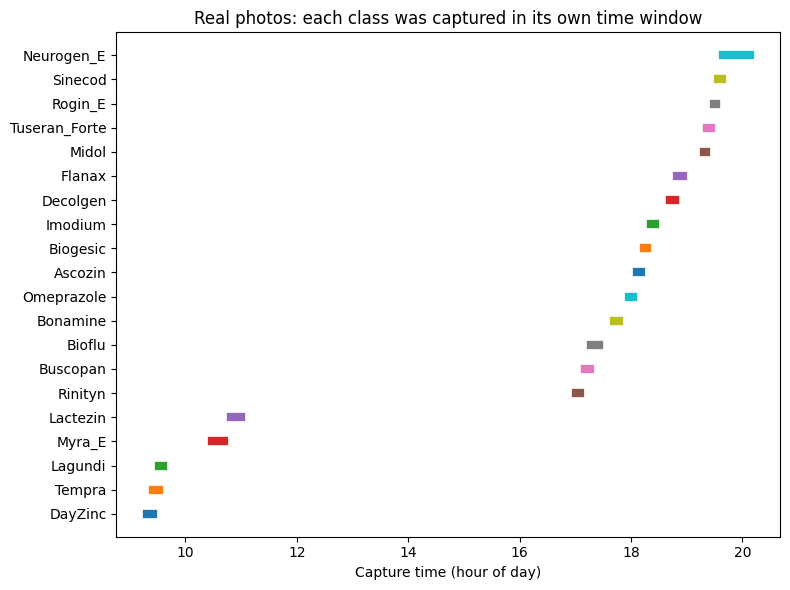

3984

In [4]:
# Class order is alphabetical and becomes the model's output order (labels.json), so don't change it.
CLASSES = sorted(meta["cls"].unique())
C = len(CLASSES)
CLS2IDX = {c: i for i, c in enumerate(CLASSES)}
meta["y"] = meta["cls"].map(CLS2IDX)

counts = meta.pivot_table(index="cls", columns="split", values="path", aggfunc="count").fillna(0).astype(int)
print(counts)
print("\nTotals:", meta["split"].value_counts().to_dict())

dup = meta.groupby("md5").agg(n=("path", "size"), splits=("split", lambda s: ",".join(sorted(set(s)))))
dup = dup[dup["n"] > 1]
cross = dup[dup["splits"].str.contains(",")]
print(f"\nExact duplicate groups: {len(dup)} | spanning more than one split: {len(cross)}")

real = meta[meta["source"] == "real"].copy()

bv = real.groupby(["cls", "split"])["burst"].apply(set).unstack()
shared = {c: len(bv.loc[c, "val"] & bv.loc[c, "test"]) for c in bv.index
          if isinstance(bv.loc[c, "val"], set) and isinstance(bv.loc[c, "test"], set)}
bursts_per_class = real.groupby("cls")["burst"].nunique()
print("\nBursts per class:", bursts_per_class.to_dict())
print("Bursts shared by Val and Test per class:", shared)

# Near-duplicate clusters inside each burst (Hamming distance <= 6 on the 64-bit hash)
def hamming(a, b):
    return bin(int(a, 16) ^ int(b, 16)).count("1")

cluster_ids = {}
for burst, g in real.sort_values("frame").groupby("burst"):
    reps = []
    for idx, h in zip(g.index, g["dhash"]):
        for k, (rh, cid) in enumerate(reps):
            if hamming(h, rh) <= 6:
                cluster_ids[idx] = cid
                break
        else:
            cid = f"{burst}#{len(reps)}"
            reps.append((h, cid))
            cluster_ids[idx] = cid
real["dup_cluster"] = pd.Series(cluster_ids)
meta.loc[real.index, "dup_cluster"] = real["dup_cluster"]
print(f"Real frames: {len(real)} | near-duplicate clusters: {real['dup_cluster'].nunique()} | bursts: {real['burst'].nunique()}")

win = (real.dropna(subset=["capture_hhmm"]).groupby("cls")["capture_hhmm"]
       .agg(["min", "max"]).sort_values("min"))
print("\nCapture window per class:")
print(win.to_string())

fig, ax = plt.subplots(figsize=(8, 6))
for i, (c, r) in enumerate(win.iterrows()):
    t0_ = int(r["min"][:2]) * 60 + int(r["min"][3:])
    t1_ = int(r["max"][:2]) * 60 + int(r["max"][3:])
    ax.plot([t0_ / 60, max(t1_, t0_ + 1) / 60], [i, i], lw=6)
ax.set_yticks(range(len(win)))
ax.set_yticklabels(win.index)
ax.set_xlabel("Capture time (hour of day)")
ax.set_title("Real photos: each class was captured in its own time window")
fig.tight_layout()
fig.savefig(FIG_DIR / "capture_windows.png", dpi=150)
plt.show()

audit = {
    "counts": counts.to_dict(),
    "totals": meta["split"].value_counts().to_dict(),
    "exact_duplicate_groups": int(len(dup)),
    "exact_duplicates_across_splits": int(len(cross)),
    "bursts_per_class": bursts_per_class.to_dict(),
    "val_test_shared_bursts": shared,
    "real_frames": int(len(real)),
    "near_duplicate_clusters": int(real["dup_cluster"].nunique()),
    "capture_window": win.to_dict(orient="index"),
    "real_size_counts": {f"{w}x{h}": int(n) for (w, h), n in
                         real.groupby(["width", "height"]).size().sort_values(ascending=False).head(5).items()},
}
(OUT / "audit.json").write_text(json.dumps(audit, indent=2, default=str))

## 4. Splits

Synthetic images are split 90/10 into training and validation. The Val and Test folders are merged into one pool of real photos, since they share bursts. For each product we hold out 4 bursts as **dev** (for picking the best epoch and calibrating) and keep the rest as **test**, and no burst ends up in both. For calibration we take one frame per dev burst, so the sample size is the number of bursts, not frames.

In [5]:
# Same SEED, same split, so an eval-only run tests on exactly the same photos.
rng = np.random.default_rng(SEED)
meta["role"] = None

syn_idx = np.array(meta.index[meta["source"] == "synthetic"], copy=True)
rng.shuffle(syn_idx)
n_val = int(len(syn_idx) * SYN_VAL_FRAC)
meta.loc[syn_idx[:n_val], "role"] = "syn_val"
meta.loc[syn_idx[n_val:], "role"] = "syn_train"

meta["is_cal"] = False
for c in CLASSES:
    bursts = sorted(meta.loc[(meta["source"] == "real") & (meta["cls"] == c), "burst"].unique())
    rng.shuffle(bursts)
    k = min(DEV_BURSTS_PER_CLASS, max(1, len(bursts) // 3))
    dev, test = set(bursts[:k]), set(bursts[k:])
    real_c = (meta["source"] == "real") & (meta["cls"] == c)
    meta.loc[real_c & meta["burst"].isin(dev), "role"] = "real_dev"
    meta.loc[real_c & meta["burst"].isin(test), "role"] = "real_test"
    for b in dev:
        idx = meta.index[real_c & (meta["burst"] == b)].to_numpy()
        meta.loc[rng.choice(idx), "is_cal"] = True

print(meta["role"].value_counts())
print("Calibration frames (one per dev burst):", int(meta["is_cal"].sum()))
assert meta["role"].notna().all()
assert not (set(meta.loc[meta.role == "real_dev", "burst"]) & set(meta.loc[meta.role == "real_test", "burst"]))
meta.drop(columns=["light"]).to_csv(OUT / "metadata.csv", index=False)

role
syn_train    36000
real_test     8724
syn_val       4000
real_dev      2379
Name: count, dtype: int64
Calibration frames (one per dev burst): 80


## 5. Lighting-only baseline

Each product in Capsure was photographed in its own time slot, so the lighting alone gives away the product. To see how much, we train a simple classifier on lighting numbers only (color averages and a brightness histogram). It got 14.1% per burst against 5% chance, which is why we never train on the real photos: a model could learn the lighting instead of the packaging.

In [6]:
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import GroupKFold, cross_val_predict


def wilson(k, n, z=1.96):
    if n == 0:
        return (float("nan"), float("nan"))
    p = k / n
    den = 1 + z * z / n
    centre = (p + z * z / (2 * n)) / den
    half = z * math.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / den
    return (centre - half, centre + half)


R = meta[meta["source"] == "real"]
X = np.array(R["light"].tolist(), dtype=np.float32)
y = R["y"].to_numpy()
groups = R["burst"].to_numpy()
n_splits = min(5, len(np.unique(groups)))
clf = make_pipeline(StandardScaler(), LogisticRegression(max_iter=3000))
pred = cross_val_predict(clf, X, y, groups=groups, cv=GroupKFold(n_splits=n_splits))
acc = float((pred == y).mean())

bdf = pd.DataFrame({"burst": groups, "y": y, "p": pred})
bvote = bdf.groupby("burst").agg(y=("y", "first"), p=("p", lambda s: s.mode().iloc[0]))
bk, bn = int((bvote["y"] == bvote["p"]).sum()), len(bvote)
lighting = {
    "frame_accuracy": acc,
    "burst_accuracy": bk / bn,
    "burst_accuracy_wilson95": wilson(bk, bn),
    "n_bursts": bn,
    "chance": 1 / C,
}
print(json.dumps(lighting, indent=2))
(OUT / "lighting_baseline.json").write_text(json.dumps(lighting, indent=2))

{
  "frame_accuracy": 0.1291542826263172,
  "burst_accuracy": 0.14133333333333334,
  "burst_accuracy_wilson95": [
    0.10970213512442653,
    0.18023856832524746
  ],
  "n_bursts": 375,
  "chance": 0.05
}


205

## 6. Product identification: ResNet-18 trained on synthetic images

We fine-tune an ImageNet ResNet-18 on the synthetic images. The augmentations try to make them look like the real phone photos: narrow crops padded back to a square, perspective, color shifts, blur, downscaling (the real photos are only 300 × 135 px) and JPEG artifacts. No horizontal flips, since mirrored text never shows up on real packs.

In [7]:
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
import torchvision
from torchvision import transforms as T

torch.manual_seed(SEED)
torch.backends.cudnn.benchmark = True
device = "cuda" if torch.cuda.is_available() else "cpu"
use_amp = device == "cuda"
print("Device:", device, "| torch", torch.__version__, "| torchvision", torchvision.__version__)

MEAN, STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]


class RandomLetterbox:
    # Crop a random narrow vertical strip and pad it back to a square, like the portrait real photos.
    def __init__(self, p=0.5, min_aspect=0.4):
        self.p, self.min_aspect = p, min_aspect

    def __call__(self, img):
        if random.random() > self.p:
            return img
        w, h = img.size
        a = random.uniform(self.min_aspect, 1.0)
        nw = max(8, int(w * a))
        x0 = random.randint(0, w - nw)
        return letterbox(img.crop((x0, 0, x0 + nw, h))).resize((w, h), Image.BILINEAR)


class RandomDownUp:
    def __init__(self, p=0.5, lo=80, hi=160):
        self.p, self.lo, self.hi = p, lo, hi

    def __call__(self, img):
        if random.random() > self.p:
            return img
        s = random.randint(self.lo, self.hi)
        return img.resize((s, s), Image.BILINEAR).resize(img.size, Image.BILINEAR)


class RandomJPEG:
    def __init__(self, p=0.5, lo=30, hi=90):
        self.p, self.lo, self.hi = p, lo, hi

    def __call__(self, img):
        if random.random() > self.p:
            return img
        buf = io.BytesIO()
        img.save(buf, format="JPEG", quality=random.randint(self.lo, self.hi))
        buf.seek(0)
        return Image.open(buf).convert("RGB")


train_tf = T.Compose([
    RandomLetterbox(0.8 if AUG_V2 else 0.5),
    T.RandomResizedCrop(IMG, scale=(0.3, 1.0) if AUG_V2 else (0.5, 1.0), ratio=(0.75, 1.33)),
    T.RandomApply([T.RandomPerspective(distortion_scale=0.2, p=1.0)], p=0.3),
    T.ColorJitter(0.3, 0.3, 0.3, 0.05),
    T.RandomApply([T.GaussianBlur(5, sigma=(0.1, 2.0))], p=0.3),
    # Real photos are about 300 x 135 px, so a pack covers far fewer than 160 px; AUG_V2 goes down to 40 px.
    RandomDownUp(0.5, lo=40, hi=100) if AUG_V2 else RandomDownUp(0.5),
    RandomJPEG(0.5),
    T.ToTensor(),
    T.Normalize(MEAN, STD),
])
eval_tf = T.Compose([T.Resize((IMG, IMG)), T.ToTensor(), T.Normalize(MEAN, STD)])


class ImgDS(Dataset):
    def __init__(self, df, tf):
        self.paths = df["cache"].tolist()
        self.ys = df["y"].astype(int).tolist()
        self.tf = tf

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, i):
        return self.tf(Image.open(self.paths[i]).convert("RGB")), self.ys[i]


def loader(df, tf, shuffle, bs=BATCH):
    return DataLoader(ImgDS(df, tf), batch_size=bs, shuffle=shuffle, num_workers=NUM_WORKERS,
                      pin_memory=(device == "cuda"), persistent_workers=NUM_WORKERS > 0,
                      drop_last=shuffle)


syn_train = meta[meta.role == "syn_train"]
syn_val = meta[meta.role == "syn_val"]
real_dev = meta[meta.role == "real_dev"]
real_test = meta[meta.role == "real_test"]
dl_train = loader(syn_train, train_tf, True)
dl_synval = loader(syn_val, eval_tf, False)
dl_dev = loader(real_dev, eval_tf, False)
print(len(syn_train), "train |", len(syn_val), "syn val |", len(real_dev), "real dev |", len(real_test), "real test")

Device: cuda | torch 2.11.0+cu128 | torchvision 0.26.0+cu128
36000 train | 4000 syn val | 2379 real dev | 8724 real test


In [8]:
model = torchvision.models.resnet18(weights=torchvision.models.ResNet18_Weights.IMAGENET1K_V1)
model.fc = nn.Linear(model.fc.in_features, C)
model = model.to(device)

if EVAL_WEIGHTS:
    # Eval-only: put the saved weights where the rest of the notebook expects them.
    _src = None
    if EVAL_WEIGHTS == "auto":
        for _base in [Path("/kaggle/input"), Path("/content/drive/MyDrive/SureCure"), Path("/content")]:
            if _base.exists():
                _src = next((p_ for p_ in _base.rglob("best.pt")), None)
                if _src is not None:
                    break
    else:
        _src = Path(EVAL_WEIGHTS)
        if _src.is_dir():
            _src = next(_src.rglob("best.pt"), None)
    if _src is None or not Path(_src).exists():
        raise FileNotFoundError(f"SC_EVAL_WEIGHTS={EVAL_WEIGHTS!r}: no best.pt found. Attach the run output or give the full path.")
    if Path(_src).resolve() != (MODEL_DIR / "best.pt").resolve():
        shutil.copy(_src, MODEL_DIR / "best.pt")
    print("Eval-only: using weights from", _src)

opt = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
steps = max(1, EPOCHS * len(dl_train))
sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=LR, total_steps=steps, pct_start=0.1)
crit = nn.CrossEntropyLoss(label_smoothing=LABEL_SMOOTHING)
try:
    scaler = torch.amp.GradScaler("cuda", enabled=use_amp)
except (AttributeError, TypeError):
    scaler = torch.cuda.amp.GradScaler(enabled=use_amp)


@torch.no_grad()
def predict(m, dl):
    m.eval()
    out = []
    for x, _ in dl:
        with torch.autocast(device_type=device, dtype=torch.float16, enabled=use_amp):
            out.append(m(x.to(device, non_blocking=True)).float().cpu())
    return torch.cat(out)


# Keep whichever epoch does best on the real dev photos, not on synthetic validation.
history, best = [], (-1.0, None)
for ep in range(EPOCHS):
    model.train()
    t0, tot, n = time.time(), 0.0, 0
    for x, yb in dl_train:
        x, yb = x.to(device, non_blocking=True), yb.to(device, non_blocking=True)
        opt.zero_grad(set_to_none=True)
        with torch.autocast(device_type=device, dtype=torch.float16, enabled=use_amp):
            loss = crit(model(x), yb)
        scaler.scale(loss).backward()
        scaler.step(opt)
        scaler.update()
        sched.step()
        tot += loss.item() * len(yb)
        n += len(yb)
    syn_acc = float((predict(model, dl_synval).argmax(1).numpy() == syn_val["y"].to_numpy()).mean())
    dev_acc = float((predict(model, dl_dev).argmax(1).numpy() == real_dev["y"].to_numpy()).mean())
    history.append({"epoch": ep + 1, "train_loss": tot / max(n, 1), "syn_val_acc": syn_acc,
                    "real_dev_acc": dev_acc, "seconds": time.time() - t0})
    print(history[-1])
    if dev_acc > best[0]:
        best = (dev_acc, ep + 1)
        torch.save(model.state_dict(), MODEL_DIR / "best.pt")
    if minutes_left() - RESERVE_MIN < history[-1]["seconds"] / 60:
        print(f"Time budget: stopping after epoch {ep + 1} ({minutes_left():.0f} min left of {TIME_BUDGET_MIN:.0f}); "
              "the best checkpoint so far is kept.")
        break

pd.DataFrame(history).to_csv(OUT / "history.csv", index=False)
model.load_state_dict(torch.load(MODEL_DIR / "best.pt", map_location=device))
print("Best epoch by real-dev accuracy:", best[1], "| dev acc:", round(best[0], 4))

h = pd.DataFrame(history)
if len(h):
    fig, ax = plt.subplots(figsize=(6, 4))
    ax.plot(h["epoch"], h["syn_val_acc"], marker="o", label="synthetic validation")
    ax.plot(h["epoch"], h["real_dev_acc"], marker="o", label="real dev bursts")
    ax.set_xlabel("Epoch"); ax.set_ylabel("Top-1 accuracy"); ax.set_ylim(0, 1); ax.legend()
    ax.set_title("Synthetic-to-real gap during training")
    fig.tight_layout(); fig.savefig(FIG_DIR / "training_curves.png", dpi=150); plt.show()

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 183MB/s]


Eval-only: using weights from /kaggle/input/datasets/rellegabrinao/surecure-v7-weights/best.pt
Best epoch by real-dev accuracy: None | dev acc: -1.0


## 6a. Fine-tune on team photos

We tried fine-tuning on our own photos (181 photos of Bonamine, Myra E and Tempra). It didn't work: accuracy on those three barely moved, and the other 17 products dropped from 0.427 to 0.336 because the model learned "real-looking photo means one of these three". The safeguard in this cell caught that and kept the original model. The final model isn't fine-tuned, and this cell skips itself in eval-only mode or when no team photos are attached.

To try again: put photos in `<product>/<session>/<photo>.jpg` (`scripts/prepare_team_photos.py` does this), ideally all 20 products with several sessions each. Sessions are split 4/1/1 into train/dev/test so photos from one sitting never land on both sides. The fine-tune is only kept if it helps the photographed products and doesn't hurt the others by more than `FT_MAX_OTHER_DROP`.

In [9]:
from concurrent.futures import ThreadPoolExecutor


def norm_name(s_):
    return re.sub(r"[^a-z0-9]", "", s_.lower())


CLS_BY_NORM = {norm_name(c): c for c in CLASSES}
for k_, v_ in LABEL_FIX.items():
    CLS_BY_NORM[norm_name(k_)] = v_


def iter_dirs(base, depth=4):
    frontier = [base]
    for _ in range(depth):
        nxt = []
        for p_ in frontier:
            try:
                for c_ in p_.iterdir():
                    if c_.is_dir() and c_.name not in {"Capsure Dataset", "drive", "sample_data", "cache",
                                                       "surecure_out", "surecure_model", "figures", "golden", ".git"}:
                        yield c_
                        nxt.append(c_)
            except (PermissionError, OSError):
                pass
        frontier = nxt


def find_team_dir():
    if TEAM_DIR:
        return Path(TEAM_DIR) if Path(TEAM_DIR).exists() else None
    for base in [Path("/kaggle/input"), Path.home() / ".cache" / "kagglehub", Path("/content/drive/MyDrive/SureCure"),
                 Path("/kaggle/temp"), Path("/kaggle/working"), Path("/content")]:
        if not base.exists():
            continue
        for d in iter_dirs(base, depth=6):
            if "team" in str(d).lower() or "med-image" in str(d).lower():
                kids = {norm_name(k.name) for k in d.iterdir() if k.is_dir()}
                if len(kids & set(CLS_BY_NORM)) >= 5:
                    return d
    return None


_found = find_team_dir()
if TEAM_DIR and _found is None:
    print("WARNING: SC_TEAM_DIR does not exist:", TEAM_DIR)
TEAM_DIR = str(_found) if _found is not None else ""
HAVE_TEAM = bool(TEAM_DIR) and not EVAL_WEIGHTS
if TEAM_DIR and EVAL_WEIGHTS:
    print("Eval-only mode: team photos found but fine-tuning is skipped.")
team = pd.DataFrame(columns=["path", "cls", "y", "session", "cache", "group", "role"])
FT_REPORT = {"used": False}

if not HAVE_TEAM:
    print("No team-photo folder found: fine-tuning is skipped. Attach one or set SC_TEAM_DIR.")
else:
    rows_t, skipped = [], []
    for pdir in sorted(p_ for p_ in Path(TEAM_DIR).iterdir() if p_.is_dir()):
        cls = CLS_BY_NORM.get(norm_name(pdir.name))
        if cls is None:
            skipped.append(pdir.name)
            continue
        for f in sorted(p_ for p_ in pdir.rglob("*") if p_.suffix.lower() in IMG_EXT):
            rel = f.relative_to(pdir)
            rows_t.append({"path": str(f), "cls": cls, "y": CLS2IDX[cls],
                           "session": rel.parts[0] if len(rel.parts) > 1 else None,
                           "cache": str(CACHE_DIR / "team" / cls / (hashlib.md5(str(f).encode()).hexdigest()[:12] + ".jpg"))})
    team = pd.DataFrame(rows_t)
    if skipped:
        print("WARNING: folders that match no product were skipped:", skipped)
    if team.empty:
        print("WARNING: the team folder has no usable photos; fine-tuning is skipped.")
        HAVE_TEAM = False

if HAVE_TEAM:
    counts_t = team["cls"].value_counts()
    few = sorted(counts_t[counts_t < FT_MIN_PHOTOS].index)
    if few:
        print(f"Left out of fine-tuning (fewer than {FT_MIN_PHOTOS} photos):", {c: int(counts_t[c]) for c in few})
        team = team[~team["cls"].isin(few)].reset_index(drop=True)
    SPLIT_MODE = FT_SPLIT if FT_SPLIT in ("session", "none") else ("session" if team["session"].notna().all() else "none")
    print("Team-photo split mode:", SPLIT_MODE)
    nos = team["session"].isna()
    if nos.any() and SPLIT_MODE == "session":
        print(f"WARNING: {int(nos.sum())} photos sit directly in a product folder. Sessions are assigned by file order "
              "(6 chunks), which only works if file names follow capture time. Prefer <product>/<session>/ folders.")
        for c, g in team[nos].groupby("cls"):
            for j, idx in enumerate(np.array_split(g.sort_values("path").index.to_numpy(), 6)):
                team.loc[idx, "session"] = f"chunk{j}"
    team["group"] = team["cls"] + "/" + team["session"].astype(str)

    with ThreadPoolExecutor(max_workers=16) as ex:
        res_t = list(ex.map(process, zip(team["path"], team["cache"], [True] * len(team))))
    team = pd.concat([team.reset_index(drop=True), pd.DataFrame(res_t)], axis=1)

    # Session-level split per product: 4 train, 1 dev, 1 test
    rng_t = np.random.default_rng(SEED)
    team["role"] = "team_train"
    too_few = []
    for c, g in team.groupby("cls"):
        sess = sorted(g["session"].unique())
        rng_t.shuffle(sess)
        if len(sess) >= 3:
            team.loc[g.index[(g["session"] == sess[-1]).to_numpy()], "role"] = "team_test"
            team.loc[g.index[(g["session"] == sess[-2]).to_numpy()], "role"] = "team_dev"
        else:
            too_few.append(c)
    if too_few and SPLIT_MODE == "session":
        print("WARNING: fewer than 3 sessions, so all photos are used for training and none for checking:", too_few)
    if SPLIT_MODE == "none":
        team["role"] = "team_train"
        print("All team photos are used for training; fine-tuning is judged on Capsure real-dev photos.")
    missing = sorted(set(CLASSES) - set(team["cls"]))
    print(team.pivot_table(index="cls", columns="role", values="path", aggfunc="count").fillna(0).astype(int))
    print("Products with no team photos:", missing or "none")

    dup_t = int(team["md5"].isin(set(meta["md5"])).sum())
    if dup_t:
        print(f"WARNING: {dup_t} team photos are byte-identical to Capsure files; they are not new photos.")

    Xt = np.array(team["light"].tolist(), dtype=np.float32)
    gt = team["group"].to_numpy()
    if SPLIT_MODE == "session" and len(np.unique(gt)) >= 3 and team["y"].nunique() >= 2:
        pred_t = cross_val_predict(make_pipeline(StandardScaler(), LogisticRegression(max_iter=3000)), Xt,
                                   team["y"].to_numpy(), groups=gt, cv=GroupKFold(n_splits=min(5, len(np.unique(gt)))))
        team_light = float((pred_t == team["y"].to_numpy()).mean())
        print(f"Lighting-only baseline on team photos: {team_light:.3f} (chance {1 / team['y'].nunique():.3f}). "
              "Far above chance means lighting differs by product and the photo protocol should be fixed.")
    else:
        team_light = None
    team_train = team[team.role == "team_train"]
    team_dev = team[team.role == "team_dev"]
    team_test = team[team.role == "team_test"]
    FT_REPORT.update({"team_dir": TEAM_DIR, "n_photos": int(len(team)), "n_sessions": int(team["group"].nunique()),
                      "roles": team["role"].value_counts().to_dict(), "products_missing": missing,
                      "duplicates_of_capsure": dup_t, "lighting_baseline_team": team_light})

No team-photo folder found: fine-tuning is skipped. Attach one or set SC_TEAM_DIR.


In [10]:
import copy


def acc_df(m, df):
    if len(df) == 0:
        return float("nan")
    return float((predict(m, loader(df, eval_tf, False)).argmax(1).numpy() == df["y"].astype(int).to_numpy()).mean())


def per_product(m, df):
    # Majority vote over each product's test session: the honest unit is the session, not the photo.
    if len(df) == 0:
        return 0, 0
    d = df.assign(p=predict(m, loader(df, eval_tf, False)).argmax(1).numpy())
    v = d.groupby("group").agg(y=("y", "first"), p=("p", lambda s_: s_.mode().iloc[0]))
    return int((v["y"].astype(int) == v["p"]).sum()), int(len(v))


if HAVE_TEAM and len(team_train) and minutes_left() - RESERVE_MIN < 5:
    print(f"Time budget: only {minutes_left():.0f} min left, fine-tuning skipped.")
    FT_REPORT["skipped_for_time"] = True
elif HAVE_TEAM and len(team_train):
    base_state = copy.deepcopy(model.state_dict())
    photographed = sorted(set(team_train["cls"]))
    rd_in, rd_out = real_dev[real_dev["cls"].isin(photographed)], real_dev[~real_dev["cls"].isin(photographed)]
    print("Products with team photos:", photographed)
    kb, nb = per_product(model, team_test)
    before = {"team_dev": acc_df(model, team_dev), "team_test_photo": acc_df(model, team_test),
              "team_test_product": kb / nb if nb else float("nan"), "real_dev": acc_df(model, real_dev)}
    before.update({"real_dev_photographed": acc_df(model, rd_in), "real_dev_other": acc_df(model, rd_out)})
    print("Synthetic-only model:", json.dumps(before))

    for name, p_ in model.named_parameters():
        p_.requires_grad = not name.startswith(FT_FREEZE)
    ft_opt = torch.optim.AdamW([p_ for p_ in model.parameters() if p_.requires_grad], lr=FT_LR, weight_decay=WEIGHT_DECAY)
    n_syn = int(len(team_train) * FT_SYN_RATIO)
    bs_ft = max(2, min(FT_BATCH, len(team_train) + n_syn))
    steps_ep = max(1, (len(team_train) + n_syn) // bs_ft)
    ft_sched = torch.optim.lr_scheduler.CosineAnnealingLR(ft_opt, T_max=FT_EPOCHS * steps_ep)
    frozen = [getattr(model, n_) for n_ in FT_FREEZE]
    ft_hist, best_ft = [], (-1.0, None, None)
    for ep in range(FT_EPOCHS):
        syn_s = syn_train.sample(min(n_syn, len(syn_train)), random_state=SEED + ep)
        mix = pd.concat([team_train[["cache", "y"]], syn_s[["cache", "y"]]], ignore_index=True)
        mix["y"] = mix["y"].astype(int)
        model.train()
        for m_ in frozen:
            m_.eval()
        t0, tot, n = time.time(), 0.0, 0
        for x, yb in loader(mix, train_tf, True, bs=bs_ft):
            x, yb = x.to(device, non_blocking=True), yb.to(device, non_blocking=True)
            ft_opt.zero_grad(set_to_none=True)
            with torch.autocast(device_type=device, dtype=torch.float16, enabled=use_amp):
                loss = crit(model(x), yb)
            scaler.scale(loss).backward()
            scaler.step(ft_opt)
            scaler.update()
            ft_sched.step()
            tot += loss.item() * len(yb)
            n += len(yb)
        r = {"epoch": ep + 1, "train_loss": tot / max(n, 1), "team_dev_acc": acc_df(model, team_dev),
             "real_dev_acc": acc_df(model, real_dev), "seconds": time.time() - t0}
        r.update({"real_dev_photographed": acc_df(model, rd_in), "real_dev_other": acc_df(model, rd_out)})
        r["select"] = r["team_dev_acc"] if len(team_dev) else r["real_dev_photographed"]
        ft_hist.append(r)
        print(r)
        if r["select"] > best_ft[0]:
            best_ft = (r["select"], ep + 1, copy.deepcopy(model.state_dict()))
        if minutes_left() - RESERVE_MIN < r["seconds"] / 60:
            print(f"Time budget: fine-tuning stopped after epoch {ep + 1}.")
            break
    for p_ in model.parameters():
        p_.requires_grad = True

    sel_before = before["team_dev"] if len(team_dev) else before["real_dev_photographed"]
    best_row = next((h for h in ft_hist if h["epoch"] == best_ft[1]), None)
    other_ok = best_row is not None and (len(rd_out) == 0 or
                                         best_row["real_dev_other"] >= before["real_dev_other"] - FT_MAX_OTHER_DROP)
    keep_ft = best_ft[2] is not None and best_ft[0] >= sel_before + FT_MIN_GAIN and other_ok
    if best_row is not None and not other_ok:
        print(f"Reverted: real-dev accuracy of products without team photos fell from {before['real_dev_other']:.3f} "
              f"to {best_row['real_dev_other']:.3f} (more than {FT_MAX_OTHER_DROP}).")
    model.load_state_dict(best_ft[2] if keep_ft else base_state)
    if keep_ft:
        torch.save(model.state_dict(), MODEL_DIR / "finetuned.pt")
    ka, na = per_product(model, team_test)
    after = {"team_dev": acc_df(model, team_dev), "team_test_photo": acc_df(model, team_test),
             "team_test_product": ka / na if na else float("nan"), "real_dev": acc_df(model, real_dev),
             "real_dev_photographed": acc_df(model, rd_in), "real_dev_other": acc_df(model, rd_out)}
    FT_REPORT.update({"used": bool(keep_ft), "best_epoch": best_ft[1], "before": before, "after": after,
                      "team_test_product_wilson95_before": wilson(kb, nb), "team_test_product_wilson95_after": wilson(ka, na),
                      "history": ft_hist, "settings": {"FT_EPOCHS": FT_EPOCHS, "FT_LR": FT_LR, "FT_SYN_RATIO": FT_SYN_RATIO,
                                                       "FT_FREEZE": list(FT_FREEZE), "FT_MIN_GAIN": FT_MIN_GAIN,
                                                       "FT_SPLIT": SPLIT_MODE, "photographed": photographed}})
    print(f"Fine-tuned model kept: {keep_ft} (best epoch {best_ft[1]}, selection metric {best_ft[0]:.3f} vs {sel_before:.3f})")
    print("Final model:", json.dumps(after))
    pd.DataFrame(ft_hist).to_csv(OUT / "finetune_history.csv", index=False)
(OUT / "finetune.json").write_text(json.dumps(FT_REPORT, indent=2, default=float))

19

## 6b. AdaBN and confidence calibration

We tested AdaBN (Li et al., 2018), which re-estimates the BatchNorm statistics on unlabeled real photos. To keep it honest we split the dev bursts in two, adapted on one half and measured on the other. It made things worse (−6.9 points), so it's off.

Then we fit a temperature (Guo et al., 2017) so the model's confidence matches how often it's actually right; in our final run it came out at 1.11. From that we pick the confidence cut-off the app uses: below it (0.704), the app shows a short list instead of a single answer. Above it, about 95% of packaging photos were identified correctly.

AdaBN cross-fold dev accuracy: 0.4678 -> 0.3987 (gain -0.0692) | kept: False
{
  "run_name": "run_20261024_0546",
  "aug_v2": false,
  "adabn_crossfold_dev_acc_before": 0.46783078880407125,
  "adabn_crossfold_dev_acc_after": 0.39868002544529263,
  "adabn_gain": -0.06915076335877862,
  "adabn_used": false,
  "real_dev_acc_final_model": 0.46742328709541825,
  "temperature": 1.110940977180524,
  "dev_ece_before": 0.05703591563525364,
  "dev_ece_after": 0.042954330916881216,
  "confidence_threshold": 0.7043451559751407,
  "conf_target": 0.9,
  "dev_coverage_at_threshold": 0.24169819251786465
}


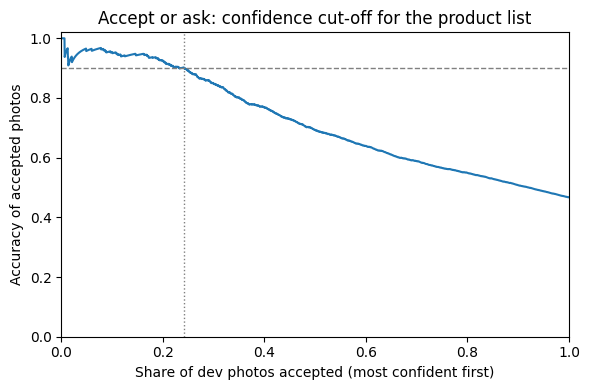

In [11]:
import copy
from scipy.optimize import minimize_scalar
from scipy.special import log_softmax, softmax


def adabn(m, df):
    # Re-estimate BatchNorm running statistics on df (labels unused); weights stay fixed.
    m2 = copy.deepcopy(m)
    for mod in m2.modules():
        if isinstance(mod, nn.BatchNorm2d):
            mod.reset_running_stats()
            mod.momentum = None
    m2.train()
    with torch.no_grad():
        for x, _ in loader(df, eval_tf, False):
            m2(x.to(device, non_blocking=True))
    return m2.eval()


def acc_on(m, df):
    return float((predict(m, loader(df, eval_tf, False)).argmax(1).numpy() == df["y"].to_numpy()).mean())


def fit_temperature(logits, y):
    def nll(logt):
        return -log_softmax(logits / np.exp(logt), axis=1)[np.arange(len(y)), y].mean()
    return float(np.exp(minimize_scalar(nll, bounds=(-3, 3), method="bounded").x))


def ece(probs, y, bins=15):
    conf, pred = probs.max(1), probs.argmax(1)
    edges = np.linspace(0, 1, bins + 1)
    e = 0.0
    for lo, hi in zip(edges[:-1], edges[1:]):
        m = (conf > lo) & (conf <= hi)
        if m.any():
            e += m.mean() * abs((pred[m] == y[m]).mean() - conf[m].mean())
    return float(e)


def confidence_threshold(probs, y, target):
    # Smallest confidence cut-off whose accepted predictions reach the target accuracy.
    conf, ok = probs.max(1), probs.argmax(1) == y
    order = np.argsort(-conf)
    run_acc = np.cumsum(ok[order]) / np.arange(1, len(ok) + 1)
    good = np.where(run_acc >= target)[0]
    if len(good) == 0:
        return 1.0, 0.0
    i = good.max()
    return float(conf[order][i]), float((i + 1) / len(ok))


fold_of = {}
for c, g in real_dev.groupby("cls"):
    for j, b in enumerate(sorted(g["burst"].unique())):
        fold_of[b] = j % 2
dev_fold = real_dev["burst"].map(fold_of)
base_accs, ada_accs = [], []
for f in (0, 1):
    adapt_df, eval_df = real_dev[dev_fold == f], real_dev[dev_fold != f]
    if len(adapt_df) == 0 or len(eval_df) == 0:
        continue
    base_accs.append(acc_on(model, eval_df))
    ada_accs.append(acc_on(adabn(model, adapt_df), eval_df))
gain = float(np.mean(ada_accs) - np.mean(base_accs)) if base_accs else float("nan")
USE_ADABN = (ADABN == "1") or (ADABN == "auto" and gain >= ADABN_MIN_GAIN)
print(f"AdaBN cross-fold dev accuracy: {np.mean(base_accs):.4f} -> {np.mean(ada_accs):.4f} "
      f"(gain {gain:+.4f}) | kept: {USE_ADABN}")
if USE_ADABN:
    model = adabn(model, real_dev)
    torch.save(model.state_dict(), MODEL_DIR / "final_adabn.pt")

logits_dev = predict(model, dl_dev).numpy().astype(np.float64)
y_dev = real_dev["y"].to_numpy()
TEMP = fit_temperature(logits_dev, y_dev)
p_raw, p_cal = softmax(logits_dev, axis=1), softmax(logits_dev / TEMP, axis=1)
CONF_T, coverage = confidence_threshold(p_cal, y_dev, CONF_TARGET)
calib = {
    "run_name": RUN_NAME, "aug_v2": AUG_V2,
    "adabn_crossfold_dev_acc_before": float(np.mean(base_accs)) if base_accs else None,
    "adabn_crossfold_dev_acc_after": float(np.mean(ada_accs)) if ada_accs else None,
    "adabn_gain": gain, "adabn_used": bool(USE_ADABN),
    "real_dev_acc_final_model": float((p_cal.argmax(1) == y_dev).mean()),
    "temperature": TEMP,
    "dev_ece_before": ece(p_raw, y_dev), "dev_ece_after": ece(p_cal, y_dev),
    "confidence_threshold": CONF_T, "conf_target": CONF_TARGET,
    "dev_coverage_at_threshold": coverage,
}
print(json.dumps(calib, indent=2))
(OUT / "calibration.json").write_text(json.dumps(calib, indent=2))

conf, ok = p_cal.max(1), p_cal.argmax(1) == y_dev
order = np.argsort(-conf)
cov_ = np.arange(1, len(ok) + 1) / len(ok)
acc_ = np.cumsum(ok[order]) / np.arange(1, len(ok) + 1)
fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(cov_, acc_)
ax.axhline(CONF_TARGET, ls="--", c="gray", lw=1)
ax.axvline(coverage, ls=":", c="gray", lw=1)
ax.set_xlabel("Share of dev photos accepted (most confident first)")
ax.set_ylabel("Accuracy of accepted photos")
ax.set_ylim(0, 1.02); ax.set_xlim(0, 1)
ax.set_title("Accept or ask: confidence cut-off for the product list")
fig.tight_layout(); fig.savefig(FIG_DIR / "coverage_accuracy.png", dpi=150); plt.show()

# With team photos, app photos resemble them more than the 300 x 135 Capsure frames: refit on team-dev.
if HAVE_TEAM and len(team_dev) >= 20:
    lt_ = predict(model, loader(team_dev, eval_tf, False)).numpy().astype(np.float64)
    yt_ = team_dev["y"].astype(int).to_numpy()
    TEMP = fit_temperature(lt_, yt_)
    CONF_T, cov_team = confidence_threshold(softmax(lt_ / TEMP, axis=1), yt_, CONF_TARGET)
    calib.update({"calibrated_on": "team_dev", "temperature": TEMP, "confidence_threshold": CONF_T,
                  "team_dev_coverage_at_threshold": cov_team, "team_dev_ece_after": ece(softmax(lt_ / TEMP, axis=1), yt_)})
    print(f"Recalibrated on team-dev: T={TEMP:.3f}, cut-off={CONF_T:.3f}, coverage={cov_team:.3f}")
    (OUT / "calibration.json").write_text(json.dumps(calib, indent=2))

## 7. Test on held-out real bursts

This is the first time the test bursts are used. We report accuracy per frame, per near-duplicate cluster and per burst (majority vote); the burst number is the honest one for confidence intervals. Our final model gets 54.6% per burst (95% CI 48.9 to 60.2) across all real photos.

/tmp/ipykernel_23/3388312999.py:16: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  per_class = T_.groupby("cls").apply(lambda g: float((g["p"] == g["y"]).mean())).to_dict()


{
  "best_epoch": null,
  "synthetic_val_accuracy": 0.9845,
  "real_test_frame_accuracy": 0.48372306281522237,
  "real_test_macro_f1": 0.4981318915630836,
  "real_test_cluster_accuracy": 0.5358370801375297,
  "n_clusters": 3781,
  "real_test_burst_accuracy": 0.5457627118644067,
  "n_bursts": 295,
  "real_test_burst_accuracy_wilson95": [
    0.4887194291158826,
    0.6016294379762491
  ],
  "lighting_only_baseline_burst_accuracy": 0.14133333333333334
}


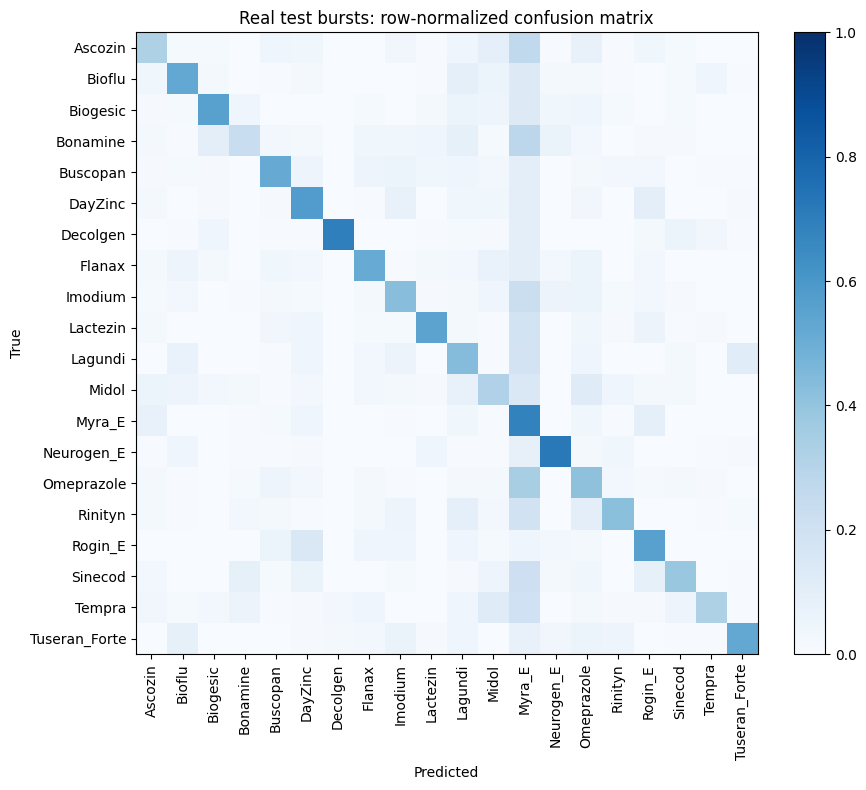

In [12]:
from sklearn.metrics import f1_score, confusion_matrix

# First time the test photos are used. Nothing below changes the model based on them.
dl_test = loader(real_test, eval_tf, False)
logits_test = predict(model, dl_test)
p_test = logits_test.argmax(1).numpy()
y_test = real_test["y"].to_numpy()

frame_acc = float((p_test == y_test).mean())
macro_f1 = float(f1_score(y_test, p_test, average="macro"))
T_ = real_test.assign(p=p_test)
clus = T_.groupby("dup_cluster").first()
clus_k, clus_n = int((clus["p"] == clus["y"]).sum()), len(clus)
bv_ = T_.groupby("burst").agg(y=("y", "first"), p=("p", lambda s: s.mode().iloc[0]))
bk_, bn_ = int((bv_["p"] == bv_["y"]).sum()), len(bv_)
per_class = T_.groupby("cls").apply(lambda g: float((g["p"] == g["y"]).mean())).to_dict()

syn_val_acc = float((predict(model, dl_synval).argmax(1).numpy() == syn_val["y"].to_numpy()).mean())
metrics = {
    "best_epoch": best[1],
    "synthetic_val_accuracy": syn_val_acc,
    "real_test_frame_accuracy": frame_acc,
    "real_test_macro_f1": macro_f1,
    "real_test_cluster_accuracy": clus_k / clus_n, "n_clusters": clus_n,
    "real_test_burst_accuracy": bk_ / bn_, "n_bursts": bn_,
    "real_test_burst_accuracy_wilson95": wilson(bk_, bn_),
    "per_class_frame_accuracy": per_class,
    "lighting_only_baseline_burst_accuracy": lighting["burst_accuracy"],
}
print(json.dumps({k: v for k, v in metrics.items() if k != "per_class_frame_accuracy"}, indent=2))

cm = confusion_matrix(y_test, p_test, labels=range(C), normalize="true")
fig, ax = plt.subplots(figsize=(9, 8))
im = ax.imshow(cm, vmin=0, vmax=1, cmap="Blues")
ax.set_xticks(range(C)); ax.set_xticklabels(CLASSES, rotation=90)
ax.set_yticks(range(C)); ax.set_yticklabels(CLASSES)
ax.set_xlabel("Predicted"); ax.set_ylabel("True")
ax.set_title("Real test bursts: row-normalized confusion matrix")
fig.colorbar(im, ax=ax, fraction=0.046)
fig.tight_layout(); fig.savefig(FIG_DIR / "confusion_matrix.png", dpi=150); plt.show()

## 7b. Accuracy by what's in the photo

Looking through the test photos, we noticed each product was shot as a box, then a blister strip, then a single loose pill. More than a third of the test bursts are loose pills, which the app never asks for. So we labeled every burst by hand (`box`, `blister` or `loose`, with `sure = 0` for the few unclear ones) and report accuracy for each.

Besides majority vote, we also average the probabilities over a burst (the closest thing to the app combining a few shots) and check top-3 (whether the right product is in the app's short list). On packaging photos the model gets 78.0%, and the right product is in the top 3 for 89.8%. Loose pills are at 18%.

Form labels: built-in copy | 375 bursts | {'loose': 137, 'box': 133, 'blister': 105}
                             n_bursts  burst_vote  burst_meanprob  burst_top3  frame_top1  accepted_share_at_cutoff  accepted_accuracy_at_cutoff
all                               295       0.546           0.559       0.702       0.484                     0.250                        0.928
packaging (box + blister)         186       0.769           0.780       0.898       0.680                     0.375                        0.952
box                               111       0.937           0.928       1.000       0.857                     0.519                        0.985
blister                            75       0.520           0.560       0.747       0.420                     0.165                        0.798
loose pill                        109       0.165           0.183       0.367       0.154                     0.038                        0.540
packaging, sure labels only       178       0

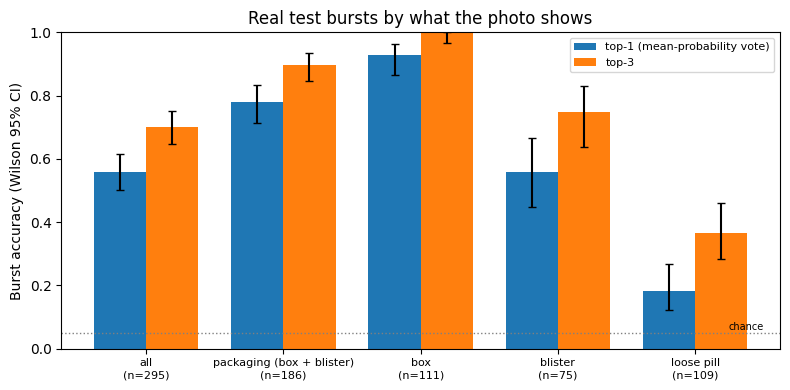

In [13]:
def find_forms_csv():
    if FORMS_CSV:
        return Path(FORMS_CSV) if Path(FORMS_CSV).exists() else None
    for base in [Path.cwd(), Path("/kaggle/input"), Path("/content"), Path("/content/drive/MyDrive/SureCure"),
                 Path("/kaggle/working")]:
        if base.exists():
            hit = next(base.rglob("capsure_burst_forms.csv"), None)
            if hit is not None:
                return hit
    return None


# Our hand labels, one letter per real burst in sorted order: b = box, s = blister strip, l = loose pill.
# Upper case means the form was hard to tell. A capsure_burst_forms.csv in the inputs overrides this.
FORMS_EMBED = {
    "Ascozin": "bbbsssllllllllllbb",
    "Bioflu": "bbbbbbsssSslllllsl",
    "Biogesic": "bbbbbbbsssssslllllll",
    "Bonamine": "bbbbbbbsssslllllll",
    "Buscopan": "bbbbbsSbbbllllllll",
    "DayZinc": "bbbbbsssssssllBlllll",
    "Decolgen": "bbbbbbbsssssllllll",
    "Flanax": "bbbbbbsssssSsllllll",
    "Imodium": "bbbbbbbssssssllllll",
    "Lactezin": "bbbbbbbsssssllllllll",
    "Lagundi": "bbbbbbbsssssslllll",
    "Midol": "bbbbbbssssssllllll",
    "Myra_E": "bbbbbssSllllssssbbbb",
    "Neurogen_E": "bbBbbbsssssslllllb",
    "Omeprazole": "bbbbBsbsslllllllll",
    "Rinityn": "bbbbbbsssslllllsss",
    "Rogin_E": "bbbbbbbssslllSllll",
    "Sinecod": "bbbbbbssssllllllll",
    "Tempra": "bbbbbbssssssllllllll",
    "Tuseran_Forte": "bbbbbbbssssslllllllll",
}


def forms_from_embed():
    letter = {"b": "box", "s": "blister", "l": "loose"}
    rows_f = []
    for c, code_ in FORMS_EMBED.items():
        bl = sorted(meta.loc[(meta["source"] == "real") & (meta["cls"] == c), "burst"].unique())
        if len(bl) != len(code_):
            print(f"WARNING: {c}: {len(bl)} real bursts in this copy of the data, {len(code_)} labels; {c} left out of 7b.")
            continue
        rows_f += [{"cls": c, "burst": b, "form": letter[ch.lower()], "sure": int(ch.islower())}
                   for b, ch in zip(bl, code_)]
    return pd.DataFrame(rows_f)


forms_path = find_forms_csv()
by_form = {}
forms = pd.read_csv(forms_path, dtype={"burst": str}) if forms_path is not None else forms_from_embed()
if forms.empty:
    print("No form labels available: section 7b skipped.")
else:
    print("Form labels:", forms_path or "built-in copy", "|", len(forms), "bursts |", forms["form"].value_counts().to_dict())
    P_test = softmax(logits_test.numpy().astype(np.float64) / TEMP, axis=1)
    top3 = np.argsort(-P_test, axis=1)[:, :3]
    F_ = real_test.assign(p=p_test, conf=P_test.max(1), in_top3=(top3 == y_test[:, None]).any(1))
    F_ = F_.merge(forms[["burst", "form", "sure"]], on="burst", how="left")
    n_missing = int(F_["form"].isna().sum())
    if n_missing:
        print(f"WARNING: {n_missing} test frames have no form label "
              f"({F_.loc[F_['form'].isna(), 'burst'].nunique()} bursts); they count only in 'all'.")
    probs_df = pd.DataFrame(P_test, index=F_.index)

    def burst_table(G):
        rows = []
        for b, g in G.groupby("burst"):
            mp = probs_df.loc[g.index].mean(axis=0).to_numpy()
            rows.append({"burst": b, "cls": g["cls"].iloc[0], "form": g["form"].iloc[0], "sure": g["sure"].iloc[0],
                         "y": int(g["y"].iloc[0]),
                         "vote_ok": int(g["p"].mode().iloc[0] == g["y"].iloc[0]),
                         "meanprob_ok": int(mp.argmax() == g["y"].iloc[0]),
                         "top3_ok": int(g["y"].iloc[0] in np.argsort(-mp)[:3])})
        return pd.DataFrame(rows)

    BT = burst_table(F_)

    def summarize(mask_b, mask_f):
        B, Fr = BT[mask_b], F_[mask_f]
        n = len(B)
        if n == 0:
            return None
        acc = Fr["conf"] >= CONF_T
        out = {"n_bursts": n, "n_frames": int(len(Fr)),
               "frame_top1": float((Fr["p"] == Fr["y"]).mean()), "frame_top3": float(Fr["in_top3"].mean())}
        for key in ("vote_ok", "meanprob_ok", "top3_ok"):
            k = int(B[key].sum())
            out[f"burst_{key[:-3]}"] = k / n
            out[f"burst_{key[:-3]}_wilson95"] = wilson(k, n)
        out["accepted_share_at_cutoff"] = float(acc.mean())
        out["accepted_accuracy_at_cutoff"] = float((Fr.loc[acc, "p"] == Fr.loc[acc, "y"]).mean()) if acc.any() else None
        return out

    groups = {"all": (BT["burst"].notna(), F_["burst"].notna()),
              "packaging (box + blister)": (BT["form"].isin(["box", "blister"]), F_["form"].isin(["box", "blister"])),
              "box": (BT["form"] == "box", F_["form"] == "box"),
              "blister": (BT["form"] == "blister", F_["form"] == "blister"),
              "loose pill": (BT["form"] == "loose", F_["form"] == "loose"),
              "packaging, sure labels only": (BT["form"].isin(["box", "blister"]) & (BT["sure"] == 1),
                                              F_["form"].isin(["box", "blister"]) & (F_["sure"] == 1))}
    for name, (mb, mf) in groups.items():
        s_ = summarize(mb, mf)
        if s_ is not None:
            by_form[name] = s_
    show = pd.DataFrame(by_form).T[["n_bursts", "burst_vote", "burst_meanprob", "burst_top3", "frame_top1",
                                    "accepted_share_at_cutoff", "accepted_accuracy_at_cutoff"]]
    print(show.apply(pd.to_numeric, errors="coerce").round(3).to_string())

    pk = BT[BT["form"].isin(["box", "blister"])]
    per_prod = pk.groupby("cls").agg(n=("burst", "size"), vote=("vote_ok", "mean"),
                                     meanprob=("meanprob_ok", "mean"), top3=("top3_ok", "mean"))
    print("\nPackaging bursts, per product:")
    print(per_prod.sort_values("meanprob").round(2).to_string())
    by_form["per_product_packaging"] = per_prod.round(4).to_dict(orient="index")

    names = [k for k in ["all", "packaging (box + blister)", "box", "blister", "loose pill"] if k in by_form]
    fig, ax = plt.subplots(figsize=(8, 4))
    xs = np.arange(len(names))
    for j, (key, lab) in enumerate([("burst_meanprob", "top-1 (mean-probability vote)"), ("burst_top3", "top-3")]):
        v = np.array([by_form[k][key] for k in names])
        lo = np.array([by_form[k][key + "_wilson95"][0] for k in names])
        hi = np.array([by_form[k][key + "_wilson95"][1] for k in names])
        ax.bar(xs + (j - 0.5) * 0.38, v, 0.38, yerr=[np.clip(v - lo, 0, None), np.clip(hi - v, 0, None)],
               capsize=3, label=lab)
    ax.set_xticks(xs); ax.set_xticklabels([f"{k}\n(n={by_form[k]['n_bursts']})" for k in names], fontsize=8)
    ax.axhline(1 / C, ls=":", c="gray", lw=1); ax.text(len(names) - 0.5, 1 / C + 0.01, "chance", fontsize=7, ha="right")
    ax.set_ylim(0, 1); ax.set_ylabel("Burst accuracy (Wilson 95% CI)"); ax.legend(fontsize=8)
    ax.set_title("Real test bursts by what the photo shows")
    fig.tight_layout(); fig.savefig(FIG_DIR / "accuracy_by_form.png", dpi=150); plt.show()

    BT.to_csv(OUT / "test_bursts_by_form.csv", index=False)
    (OUT / "accuracy_by_form.json").write_text(json.dumps(by_form, indent=2, default=float))
metrics["accuracy_by_form"] = by_form

## 8. Out-of-scope guard: Mahalanobis score

This was our first guard. It measures how far a photo's features are from the nearest product, using statistics from the synthetic training images (Lee et al., 2018), with a conformal threshold (Bates et al., 2023) set so about 5% of supported photos get wrongly rejected. It didn't hold up (see 8b) and the app doesn't use it anymore, but we kept it because the way it failed is part of the result.

In [14]:
backbone = nn.Sequential(*list(model.children())[:-1], nn.Flatten(1)).eval()


@torch.no_grad()
def features(df):
    out = []
    for x, _ in loader(df, eval_tf, False):
        out.append(backbone(x.to(device)).float().cpu())
    return torch.cat(out).numpy().astype(np.float64)


fit_df = syn_train.groupby("cls", group_keys=False).apply(
    lambda g: g.sample(min(len(g), FEATS_PER_CLASS), random_state=SEED))
F_fit = features(fit_df)
y_fit = fit_df["y"].to_numpy()
mu = np.stack([F_fit[y_fit == c].mean(0) for c in range(C)])
centered = F_fit - mu[y_fit]
cov = centered.T @ centered / len(F_fit)
cov += np.eye(cov.shape[0]) * 1e-6 * np.trace(cov) / cov.shape[0]
prec = np.linalg.inv(cov)


def maha(Fm):
    d = np.stack([np.einsum("nd,de,ne->n", Fm - mu[c], prec, Fm - mu[c]) for c in range(C)], 1)
    return d.min(1), d.argmin(1)


s_val, c_val = maha(features(syn_val))
glob_m, glob_s = s_val.mean(), s_val.std() + 1e-9
m_c = np.array([s_val[c_val == c].mean() if (c_val == c).sum() >= 10 else glob_m for c in range(C)])
sd_c = np.array([s_val[c_val == c].std() + 1e-9 if (c_val == c).sum() >= 10 else glob_s for c in range(C)])


def zscore(Fm):
    s, c = maha(Fm)
    return (s - m_c[c]) / sd_c[c]


cal = meta[meta.is_cal]
if HAVE_TEAM and GUARD_CAL == "pooled" and len(team_dev):
    # Add one team-dev photo per session so the threshold also reflects phone photos like the app's.
    cal = pd.concat([cal[["cache", "y"]], team_dev.groupby("group").sample(1, random_state=SEED)[["cache", "y"]]],
                    ignore_index=True)
    print(f"Guard calibration pool: {len(cal)} photos (Capsure dev bursts + one team-dev photo per session)")
z_cal = np.sort(zscore(features(cal)))
n_cal = len(z_cal)
k = math.ceil((n_cal + 1) * (1 - ALPHA))
if k > n_cal:
    print(f"WARNING: n_cal={n_cal} is too small for alpha={ALPHA}; threshold set to the max score.")
    k = n_cal
thr = float(z_cal[k - 1])

z_test = zscore(features(real_test))
rej = z_test > thr
T_ = T_.assign(z=z_test, rejected=rej)
one_per_burst = T_.groupby("burst").sample(1, random_state=SEED)
fr_k, fr_n = int(one_per_burst["rejected"].sum()), len(one_per_burst)
guard = {
    "alpha": ALPHA, "n_cal": n_cal, "k": k, "threshold_z": thr,
    "false_rejection_all_test_frames": float(rej.mean()),
    "false_rejection_one_frame_per_burst": fr_k / fr_n, "n_bursts": fr_n,
    "false_rejection_one_frame_per_burst_wilson95": wilson(fr_k, fr_n),
}

ood_files = [p for p in Path(OOD_DIR).rglob("*") if p.suffix.lower() in IMG_EXT] if OOD_DIR and Path(OOD_DIR).exists() else []
if ood_files:
    from sklearn.metrics import roc_auc_score
    ood_cache = []
    for i, p in enumerate(ood_files):
        dst = CACHE_DIR / "ood" / f"{i:06d}.jpg"
        process((str(p), str(dst), False))
        ood_cache.append(str(dst))
    ood_df = pd.DataFrame({"cache": ood_cache, "y": 0})
    z_ood = zscore(features(ood_df))
    labels = np.r_[np.zeros(len(one_per_burst)), np.ones(len(z_ood))]
    scores = np.r_[one_per_burst["z"].to_numpy(), z_ood]
    guard.update({"ood_n": len(z_ood), "ood_auroc_vs_one_frame_per_test_burst": float(roc_auc_score(labels, scores)),
                  "ood_detected_at_threshold": float((z_ood > thr).mean())})
else:
    print("No OOD_DIR given: AUROC against out-of-scope medicines is skipped.")
metrics["ood_guard"] = guard
print(json.dumps(guard, indent=2))
(OUT / "metrics.json").write_text(json.dumps(metrics, indent=2, default=float))

/tmp/ipykernel_23/4057538587.py:12: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  fit_df = syn_train.groupby("cls", group_keys=False).apply(


No OOD_DIR given: AUROC against out-of-scope medicines is skipped.
{
  "alpha": 0.05,
  "n_cal": 80,
  "k": 77,
  "threshold_z": 6.033319068259306,
  "false_rejection_all_test_frames": 0.04940394314534617,
  "false_rejection_one_frame_per_burst": 0.05423728813559322,
  "n_bursts": 295,
  "false_rejection_one_frame_per_burst_wilson95": [
    0.03365711099957879,
    0.08627799843632306
  ]
}


7954

## 8b. Testing the guard

We check two things: that it doesn't reject too many photos of our own products, and that it catches products outside the 20. For the second, every extra dataset attached to the notebook is treated as out-of-scope (we used `ultralytics/medical-pills`). We also hide 5 products at a time from the guard and see whether it rejects their photos; that test is optimistic, since the network was trained on all 20.

We also compare it with two simpler scores from the same network, max-softmax (Hendrycks & Gimpel, 2017) and energy (Liu et al., 2020). If the Mahalanobis guard can't beat them, there's no reason to keep it.

It couldn't. On the medical-pills photos it scored an AUROC of 0.34, worse than guessing, while energy got 0.90. The scores show why: our own real photos sit far from the synthetic ones, and the clean, high-resolution pill photos actually look *more* like the synthetic data than our phone photos do. So the guard was measuring image quality, not which product it was.

Out-of-scope sources found: {'surecure-v7-weights': '/kaggle/input/datasets/rellegabrinao/surecure-v7-weights', 'medical-pills': '/kaggle/input/datasets/ultralytics/medical-pills'}
Skipping surecure-v7-weights: only 0 images

GUARD VERDICT: NOT EFFECTIVE
 - False rejection 0.054 vs alpha 0.05: FAIL
 - medical-pills: AUROC 0.336 (95% CI 0.281 to 0.391) target FAIL; beats MSP 0.891 and energy 0.903: NO
{
  "median_z_synthetic_val": -0.26937356567395687,
  "median_z_real_calibration": 2.759890219187919,
  "median_z_real_test": 2.914595489908444,
  "threshold_z": 6.033319068259306
}


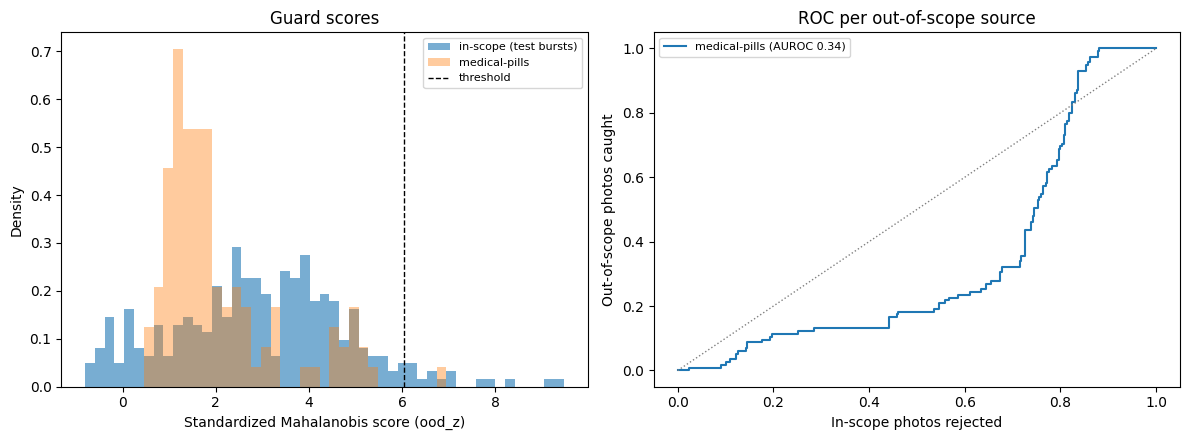

9670

In [15]:
from sklearn.metrics import roc_auc_score, roc_curve


def find_ood_sources():
    srcs = {}
    for d in ([OOD_DIR] if OOD_DIR else []) + OOD_DIRS:
        if Path(d).exists():
            srcs[Path(d).name] = Path(d)
        else:
            print("OOD folder not found:", d)
    base = Path("/kaggle/input")
    if OOD_AUTO and base.exists():
        roots = []
        for c in sorted(p for p in base.iterdir() if p.is_dir()):
            if c.name in {"datasets", "competitions", "models", "notebooks", "kernels"}:
                # Newer mount layout: /kaggle/input/datasets/<owner>/<slug>
                for owner in sorted(p for p in c.iterdir() if p.is_dir()):
                    roots += sorted(p for p in owner.iterdir() if p.is_dir())
            else:
                roots.append(c)
        for r in roots:
            if ROOT.resolve().is_relative_to(r.resolve()):
                continue
            if HAVE_TEAM and (Path(TEAM_DIR).is_relative_to(r) or Path(TEAM_DIR).resolve().is_relative_to(r.resolve())):
                continue
            if any(x.lower() in str(r).lower() for x in OOD_EXCLUDE):
                continue
            if r.name.startswith("models") or "/models/" in str(r):
                continue
            srcs.setdefault(r.name, r)
    return srcs


def list_images(folder, cap, seed=SEED):
    files = sorted(p for p in Path(folder).rglob("*") if p.suffix.lower() in IMG_EXT)
    if len(files) > cap:
        files = [files[i] for i in np.random.default_rng(seed).choice(len(files), cap, replace=False)]
    return files


def class_name_overlap(folder):
    names = {p.name.lower() for p in Path(folder).rglob("*") if p.is_dir()}
    return sorted(c for c in CLASSES if c.lower() in names)


def boot_auroc(neg, pos, n_boot=1000, seed=SEED):
    r = np.random.default_rng(seed)
    labels = np.r_[np.zeros(len(neg)), np.ones(len(pos))]
    point = float(roc_auc_score(labels, np.r_[neg, pos]))
    bs = []
    for _ in range(n_boot):
        a = neg[r.integers(0, len(neg), len(neg))]
        b = pos[r.integers(0, len(pos), len(pos))]
        bs.append(roc_auc_score(labels, np.r_[a, b]))
    lo, hi = np.percentile(bs, [2.5, 97.5])
    return point, float(lo), float(hi)


def fpr_at_95_detect(neg, pos):
    # Share of in-scope photos rejected when the cut-off catches 95% of out-of-scope photos.
    cut = np.quantile(pos, 0.05)
    return float((neg >= cut).mean())


def verdict(guard_fr, source_results, alpha=ALPHA, target=AUROC_TARGET):
    real = {k: v for k, v in source_results.items() if not k.startswith("class_holdout")}
    if not real:
        return "NOT TESTED", ["No real out-of-scope source attached; only the class-holdout ceiling is available."]
    notes, passes = [], []
    fr_ok = guard_fr <= alpha
    notes.append(f"False rejection {guard_fr:.3f} vs alpha {alpha}: {'pass' if fr_ok else 'FAIL'}")
    for k, v in real.items():
        a_ok = v["auroc_mahalanobis"] >= target
        b_ok = v["auroc_mahalanobis"] > max(v["auroc_msp"], v["auroc_energy"])
        passes.append(fr_ok and a_ok and b_ok)
        notes.append(f"{k}: AUROC {v['auroc_mahalanobis']:.3f} (95% CI {v['auroc_ci95'][0]:.3f} to {v['auroc_ci95'][1]:.3f}) "
                     f"target {'pass' if a_ok else 'FAIL'}; beats MSP {v['auroc_msp']:.3f} and energy "
                     f"{v['auroc_energy']:.3f}: {'yes' if b_ok else 'NO'}")
    if all(passes):
        return "EFFECTIVE", notes
    if any(passes):
        return "PARTIAL", notes
    return "NOT EFFECTIVE", notes


def all_scores(df_or_feats):
    Fm = features(df_or_feats) if isinstance(df_or_feats, pd.DataFrame) else df_or_feats
    with torch.no_grad():
        lg = model.fc(torch.tensor(Fm, dtype=torch.float32, device=device)).cpu().numpy().astype(np.float64)
    lg = lg / TEMP
    msp = -softmax(lg, axis=1).max(1)                      # higher = more out-of-scope
    lse = np.log(np.exp(lg - lg.max(1, keepdims=True)).sum(1)) + lg.max(1)
    energy = -TEMP * lse                                   # higher = more out-of-scope
    return {"maha": zscore(Fm), "msp": msp, "energy": energy}, Fm


in_df = real_test.loc[one_per_burst.index]
S_in, F_in = all_scores(in_df)
guard_fr = float((S_in["maha"] > thr).mean())

diag = {"median_z_synthetic_val": float(np.median(zscore(features(syn_val.sample(min(2000, len(syn_val)), random_state=SEED))))),
        "median_z_real_calibration": float(np.median(z_cal)),
        "median_z_real_test": float(np.median(S_in["maha"])),
        "threshold_z": thr}

source_results, ood_scores = {}, {}
ood_feats = {}
srcs = find_ood_sources()
print("Out-of-scope sources found:", {k: str(v) for k, v in srcs.items()} or "none")
for name, folder in srcs.items():
    files = list_images(folder, OOD_MAX_PER_SOURCE)
    if len(files) < 20:
        print(f"Skipping {name}: only {len(files)} images")
        continue
    overlap = class_name_overlap(folder)
    if overlap:
        print(f"WARNING {name}: folders named like in-scope products {overlap}. "
              "If these are packs of the 20 products, exclude this source.")
    jobs = [(str(p), str(CACHE_DIR / "ood_eval" / name / f"{i:06d}.jpg"), False) for i, p in enumerate(files)]
    # Threads, not forked processes: CUDA is already initialized at this point.
    from concurrent.futures import ThreadPoolExecutor
    with ThreadPoolExecutor(max_workers=NUM_WORKERS) as ex:
        list(ex.map(process, jobs))
    S_o, F_o = all_scores(pd.DataFrame({"cache": [j[1] for j in jobs], "y": 0}))
    ood_feats[name] = F_o
    auc, lo, hi = boot_auroc(S_in["maha"], S_o["maha"])
    source_results[name] = {
        "n_images": len(files), "folder": str(folder), "in_scope_name_overlap": overlap,
        "auroc_mahalanobis": auc, "auroc_ci95": [lo, hi],
        "auroc_msp": float(roc_auc_score(np.r_[np.zeros(len(S_in['msp'])), np.ones(len(S_o['msp']))], np.r_[S_in["msp"], S_o["msp"]])),
        "auroc_energy": float(roc_auc_score(np.r_[np.zeros(len(S_in['energy'])), np.ones(len(S_o['energy']))], np.r_[S_in["energy"], S_o["energy"]])),
        "detected_at_threshold": float((S_o["maha"] > thr).mean()),
        "in_scope_rejected_at_95pct_detection": fpr_at_95_detect(S_in["maha"], S_o["maha"]),
        "median_z": float(np.median(S_o["maha"])),
    }
    ood_scores[name] = S_o["maha"]

# Class-holdout ceiling (no extra data): hide 5 products at a time from the guard
y_in = in_df["y"].to_numpy()
perm = np.random.default_rng(SEED).permutation(C)
ho_aucs = []
for f in range(4):
    hidden = perm[f * 5:(f + 1) * 5]
    keep = np.setdiff1d(np.arange(C), hidden)
    mu_k = np.stack([F_fit[y_fit == c].mean(0) for c in keep])
    m_fit = np.isin(y_fit, keep)
    cen = F_fit[m_fit] - mu_k[np.searchsorted(keep, y_fit[m_fit])]
    cov_k = cen.T @ cen / len(cen)
    cov_k += np.eye(cov_k.shape[0]) * 1e-6 * np.trace(cov_k) / cov_k.shape[0]
    prec_k = np.linalg.inv(cov_k)
    d = np.stack([np.einsum("nd,de,ne->n", F_in - m, prec_k, F_in - m) for m in mu_k], 1).min(1)
    is_out = np.isin(y_in, hidden)
    if is_out.any() and (~is_out).any():
        ho_aucs.append(float(roc_auc_score(is_out.astype(int), d)))
if ho_aucs:
    source_results["class_holdout_ceiling"] = {"auroc_mahalanobis_mean": float(np.mean(ho_aucs)),
                                               "auroc_per_fold": ho_aucs,
                                               "note": "optimistic: the network was trained on the hidden products"}

v, notes = verdict(guard_fr, source_results)
guard_eval = {
    "run_name": RUN_NAME, "verdict": v, "notes": notes,
    "false_rejection_one_frame_per_test_burst": guard_fr,
    "false_rejection_wilson95": wilson(int((S_in["maha"] > thr).sum()), len(S_in["maha"])),
    "n_test_bursts": int(len(S_in["maha"])),
    "auroc_msp_and_energy_note": "baselines use the same network and temperature",
    "diagnostic": diag, "sources": source_results,
}
print("\nGUARD VERDICT:", v)
for n_ in notes:
    print(" -", n_)
print(json.dumps(diag, indent=2))
(OUT / "guard_eval.json").write_text(json.dumps(guard_eval, indent=2, default=float))
metrics["guard_eval"] = guard_eval
(OUT / "metrics.json").write_text(json.dumps(metrics, indent=2, default=float))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
bins = np.linspace(min([S_in["maha"].min()] + [s.min() for s in ood_scores.values()]),
                   max([S_in["maha"].max()] + [s.max() for s in ood_scores.values()]), 50)
axes[0].hist(S_in["maha"], bins=bins, density=True, alpha=0.6, label="in-scope (test bursts)")
for name, s in ood_scores.items():
    axes[0].hist(s, bins=bins, density=True, alpha=0.4, label=name[:30])
axes[0].axvline(thr, c="k", ls="--", lw=1, label="threshold")
axes[0].set_xlabel("Standardized Mahalanobis score (ood_z)"); axes[0].set_ylabel("Density")
axes[0].legend(fontsize=8); axes[0].set_title("Guard scores")
for name, s in ood_scores.items():
    fpr, tpr, _ = roc_curve(np.r_[np.zeros(len(S_in["maha"])), np.ones(len(s))], np.r_[S_in["maha"], s])
    axes[1].plot(fpr, tpr, label=f"{name[:30]} (AUROC {source_results[name]['auroc_mahalanobis']:.2f})")
axes[1].plot([0, 1], [0, 1], c="gray", lw=1, ls=":")
axes[1].set_xlabel("In-scope photos rejected"); axes[1].set_ylabel("Out-of-scope photos caught")
axes[1].legend(fontsize=8); axes[1].set_title("ROC per out-of-scope source")
fig.tight_layout(); fig.savefig(FIG_DIR / "guard_eval.png", dpi=150); plt.show()

if HAVE_TEAM and len(team_test):
    zt_ = zscore(features(team_test))
    one_t = team_test.assign(z=zt_).groupby("group").sample(1, random_state=SEED)
    k_t, n_t = int((one_t["z"] > thr).sum()), len(one_t)
    guard_eval.update({"false_rejection_team_test_one_per_session": k_t / n_t,
                       "false_rejection_team_test_wilson95": wilson(k_t, n_t),
                       "false_rejection_team_test_all_photos": float((zt_ > thr).mean())})
    print(f"Guard false rejection on team-test phone photos: {k_t}/{n_t} sessions, "
          f"{float((zt_ > thr).mean()):.3f} of all photos")
metrics["finetune"] = FT_REPORT
(OUT / "guard_eval.json").write_text(json.dumps(guard_eval, indent=2, default=float))
(OUT / "metrics.json").write_text(json.dumps(metrics, indent=2, default=float))

## 8c. Choosing the guard the app uses

We tried fixing the Mahalanobis guard by fitting it on real photos instead (2 dev bursts per product to fit, 2 to calibrate, with Ledoit–Wolf shrinkage; Ledoit & Wolf, 2004), and compared four options on equal terms: that version, the synthetic one, energy and max-softmax. Before running it, we decided the app would get whichever had the best average AUROC when 5 products at a time are hidden. The medical-pills result is only reported, not used to choose.

Energy won (0.811, against 0.786 for the synthetic Mahalanobis guard, 0.763 for max-softmax and 0.604 for the real-photo version). The real-photo version overfit: with only about 28 photos per product from 2 bursts, it barely shrank the covariance and basically memorized those bursts. With a conformal threshold on 80 calibration photos, energy wrongly rejects 6.4% of our test photos (95% CI 4.2 to 9.8). None of the options reach the 0.90 we were aiming for, so the app treats a rejected photo as "not recognized" and sends the user to the product list and code check instead of relying on the guard alone.

maha_real: fit on 556 photos from 40 bursts | calibrate on 40 photos (one per burst, 40 bursts)
Ledoit-Wolf shrinkage: 0.057
                holdout AUROC  false rej.  n_cal  ext AUROC medical-pills
maha_real               0.604       0.112   40.0                    0.590
maha_synthetic          0.786       0.054   80.0                    0.336
energy                  0.811       0.064   80.0                    0.903
msp                     0.763       0.017   80.0                    0.891

Pre-registered pick (highest class-holdout AUROC): energy | shipped: energy


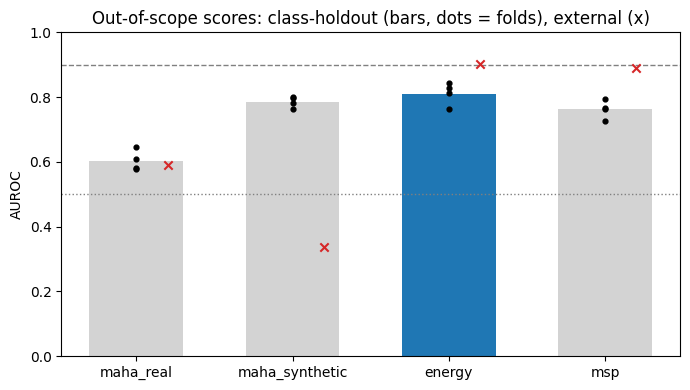

In [16]:
from sklearn.covariance import LedoitWolf

# --- 1. Real-photo fit and calibration sets (split by burst inside the dev bursts) ---
fit_b, cal_b = set(), set()
for c_, g_ in real_dev.groupby("cls"):
    for j, b in enumerate(sorted(g_["burst"].unique())):
        (fit_b if j % 2 == 0 else cal_b).add(b)
R_fit = real_dev[real_dev["burst"].isin(fit_b)]
R_fit = R_fit.groupby("dup_cluster", group_keys=False).head(1) if R_fit["dup_cluster"].notna().all() else R_fit
R_cal = real_dev[real_dev["burst"].isin(cal_b)].groupby("burst").sample(1, random_state=SEED)
F_rfit, y_rfit = features(R_fit), R_fit["y"].to_numpy().astype(int)
F_rcal, y_rcal = features(R_cal), R_cal["y"].to_numpy().astype(int)
print(f"maha_real: fit on {len(R_fit)} photos from {len(fit_b)} bursts | calibrate on {len(R_cal)} photos "
      f"(one per burst, {len(cal_b)} bursts)")


def fit_real(F, y, classes):
    classes = np.asarray(classes)
    m = np.isin(y, classes)
    F, y = F[m], y[m]
    mu_ = np.stack([F[y == c].mean(0) for c in classes])
    lw = LedoitWolf(assume_centered=True).fit(F - mu_[np.searchsorted(classes, y)])
    return mu_, lw.precision_, float(lw.shrinkage_)


def dmin(F, mu_, prec_):
    return np.stack([np.einsum("nd,de,ne->n", F - m, prec_, F - m) for m in mu_], 1).min(1)


def logit_scores(F, keep=None):
    with torch.no_grad():
        lg = model.fc(torch.tensor(F, dtype=torch.float32, device=device)).cpu().numpy().astype(np.float64) / TEMP
    if keep is not None:
        lg = lg[:, keep]
    mx = lg.max(1, keepdims=True)
    lse = np.log(np.exp(lg - mx).sum(1)) + mx[:, 0]
    return {"energy": -TEMP * lse, "msp": -softmax(lg, axis=1).max(1)}


def conformal(cal_scores, alpha=ALPHA):
    s = np.sort(np.asarray(cal_scores))
    n = len(s)
    k_ = min(math.ceil((n + 1) * (1 - alpha)), n)
    return float(s[k_ - 1]), n, k_


mu_r, prec_r, shrink_r = fit_real(F_rfit, y_rfit, np.arange(C))
print(f"Ledoit-Wolf shrinkage: {shrink_r:.3f}")


def score_all(F):
    out = {"maha_real": dmin(F, mu_r, prec_r), "maha_synthetic": zscore(F)}
    out.update(logit_scores(F))
    return out


METHODS = ["maha_real", "maha_synthetic", "energy", "msp"]

# --- 2. Class-holdout AUROC on real test photos (the selection criterion) ---
ho = {m: [] for m in METHODS}
for f in range(4):
    hidden = perm[f * 5:(f + 1) * 5]
    keep = np.setdiff1d(np.arange(C), hidden)
    is_out = np.isin(y_in, hidden).astype(int)
    mu_k, prec_k, _ = fit_real(F_rfit, y_rfit, keep)
    ls_k = logit_scores(F_in, keep)
    ho["maha_real"].append(float(roc_auc_score(is_out, dmin(F_in, mu_k, prec_k))))
    ho["energy"].append(float(roc_auc_score(is_out, ls_k["energy"])))
    ho["msp"].append(float(roc_auc_score(is_out, ls_k["msp"])))
ho["maha_synthetic"] = list(ho_aucs)
ho_mean = {m: float(np.mean(v)) if v else float("nan") for m, v in ho.items()}

# --- 3. Thresholds, false rejection on test bursts, external case studies ---
S_in_all = score_all(F_in)
S_cal80 = score_all(features(cal))
S_cal40 = score_all(F_rcal)
rows = {}
for m in METHODS:
    t_, n_, k_ = conformal(S_cal40[m] if m == "maha_real" else S_cal80[m])
    rej_ = S_in_all[m] > t_
    fr_k_ = int(rej_.sum())
    lo_, hi_ = wilson(fr_k_, len(rej_))
    rows[m] = {"class_holdout_auroc_mean": ho_mean[m], "class_holdout_auroc_per_fold": ho[m],
               "threshold": t_, "n_cal": n_, "k": k_,
               "false_rejection_one_frame_per_test_burst": fr_k_ / len(rej_),
               "false_rejection_wilson95": [lo_, hi_],
               "false_rejection_consistent_with_alpha": bool(lo_ <= ALPHA),
               "external": {}}
    for name, Fo in ood_feats.items():
        So = score_all(Fo)[m]
        rows[m]["external"][name] = {
            "n_images": int(len(So)),
            "auroc": float(roc_auc_score(np.r_[np.zeros(len(S_in_all[m])), np.ones(len(So))], np.r_[S_in_all[m], So])),
            "detected_at_threshold": float((So > t_).mean())}

# --- 4. Pre-registered choice ---
auto_pick = max(METHODS, key=lambda m: (ho_mean[m], -METHODS.index(m)))
GUARD_SCORE = auto_pick if GUARD_MODE == "auto" else GUARD_MODE
if GUARD_SCORE not in METHODS:
    raise ValueError(f"SC_GUARD_MODE={GUARD_MODE!r}: use auto, " + ", ".join(METHODS))
chosen = rows[GUARD_SCORE]
print(pd.DataFrame({m: {"holdout AUROC": r["class_holdout_auroc_mean"],
                        "false rej.": r["false_rejection_one_frame_per_test_burst"],
                        "n_cal": r["n_cal"],
                        **{f"ext AUROC {k_[:14]}": v["auroc"] for k_, v in r["external"].items()}}
                    for m, r in rows.items()}).T.round(3).to_string())
print(f"\nPre-registered pick (highest class-holdout AUROC): {auto_pick} | shipped: {GUARD_SCORE}")

# --- 5. Hand the choice to the export (section 9) ---
thr_synthetic = thr
if GUARD_SCORE == "maha_real":
    mu, prec = mu_r, prec_r
    m_c, sd_c = np.zeros(C), np.ones(C)           # ood_z = raw smallest distance
    thr, n_cal = chosen["threshold"], chosen["n_cal"]
    guard_spec = {"score": "ood_z", "threshold": thr}
elif GUARD_SCORE == "maha_synthetic":
    guard_spec = {"score": "ood_z", "threshold": thr}
else:
    guard_spec = {"score": GUARD_SCORE, "threshold": chosen["threshold"]}
guard_spec["onnx_output"] = {"ood_z": "ood_z", "energy": "energy"}.get(guard_spec["score"])
guard_spec.update({
    "method": GUARD_SCORE, "alpha": ALPHA, "n_cal": chosen["n_cal"],
    "rule": "reject the product ID (show the product list / code check) when score > threshold",
    "energy_formula": "-temperature * logsumexp(logits / temperature)",
    "msp_formula": "-max(softmax(logits / temperature))",
    "class_holdout_auroc": chosen["class_holdout_auroc_mean"],
    "false_rejection_test": chosen["false_rejection_one_frame_per_test_burst"]})


def guard_rejects(logits_row, z_value):
    # The app's rule, used for the golden test images in section 9b.
    if guard_spec["score"] == "ood_z":
        s_ = float(z_value)
    else:
        sc_ = logit_scores_from_logits(np.asarray(logits_row, dtype=np.float64)[None])
        s_ = float(sc_[guard_spec["score"]][0])
    return s_ > guard_spec["threshold"]


def logit_scores_from_logits(lg):
    lg = lg / TEMP
    mx = lg.max(1, keepdims=True)
    return {"energy": -TEMP * (np.log(np.exp(lg - mx).sum(1)) + mx[:, 0]), "msp": -softmax(lg, axis=1).max(1)}


holdout_target_met = chosen["class_holdout_auroc_mean"] >= AUROC_TARGET
guard_compare = {"run_name": RUN_NAME, "selection_rule": "highest mean class-holdout AUROC on real test photos",
                 "pre_registered_pick": auto_pick, "shipped": GUARD_SCORE, "guard_mode": GUARD_MODE,
                 "fit": {"photos": int(len(R_fit)), "bursts": len(fit_b), "ledoit_wolf_shrinkage": shrink_r},
                 "holdout_target": AUROC_TARGET, "holdout_target_met": bool(holdout_target_met),
                 "methods": rows, "app_guard": guard_spec,
                 "notes": ["class-holdout AUROC is optimistic for every method: the network saw the hidden products in training",
                           "external sources are case studies; frames from one video are not independent"]}
(OUT / "guard_compare.json").write_text(json.dumps(guard_compare, indent=2, default=float))
metrics["guard_compare"] = guard_compare
(OUT / "metrics.json").write_text(json.dumps(metrics, indent=2, default=float))

fig, ax = plt.subplots(figsize=(7, 4))
for i, m in enumerate(METHODS):
    ax.bar(i, ho_mean[m], 0.6, color="tab:blue" if m == GUARD_SCORE else "lightgray")
    ax.scatter([i] * len(ho[m]), ho[m], s=12, c="k", zorder=3)
    for name, v in rows[m]["external"].items():
        ax.scatter(i + 0.2, v["auroc"], marker="x", c="tab:red", zorder=3)
ax.axhline(AUROC_TARGET, ls="--", c="gray", lw=1)
ax.axhline(0.5, ls=":", c="gray", lw=1)
ax.set_xticks(range(len(METHODS))); ax.set_xticklabels(METHODS)
ax.set_ylim(0, 1); ax.set_ylabel("AUROC")
ax.set_title("Out-of-scope scores: class-holdout (bars, dots = folds), external (x)")
fig.tight_layout(); fig.savefig(FIG_DIR / "guard_compare.png", dpi=150); plt.show()

## 9. Export to ONNX for the Android app

We export one ONNX file with three outputs: `logits` (20 product scores, in `labels.json` order), `energy` (the guard score, already computed with the temperature) and `ood_z` (the old Mahalanobis score, which the app ignores). The app rejects a photo when `energy` is above `guard.threshold` in `meta.json`.

The input is a 1 × 3 × 224 × 224 RGB image in 0..1: rotated upright from EXIF, padded to a square with `fill_rgb`, then resized. Normalization happens inside the model.

In [17]:
class SureCureNet(nn.Module):
    def __init__(self, model):
        super().__init__()
        self.backbone = nn.Sequential(*list(model.children())[:-1], nn.Flatten(1))
        self.fc = model.fc
        self.register_buffer("img_mean", torch.tensor(MEAN).view(1, 3, 1, 1))
        self.register_buffer("img_std", torch.tensor(STD).view(1, 3, 1, 1))
        self.register_buffer("mu", torch.tensor(mu, dtype=torch.float32))
        self.register_buffer("prec", torch.tensor(prec, dtype=torch.float32))
        self.register_buffer("m_c", torch.tensor(m_c, dtype=torch.float32))
        self.register_buffer("sd_c", torch.tensor(sd_c, dtype=torch.float32))
        # Temperature from section 6b, baked in so the app reads the energy score directly.
        self.register_buffer("temp", torch.tensor(float(TEMP), dtype=torch.float32))

    def forward(self, x):
        f = self.backbone((x - self.img_mean) / self.img_std)   # ImageNet normalization inside the graph
        logits = self.fc(f)
        diff = f.unsqueeze(1) - self.mu.unsqueeze(0)            # B x C x D
        d = (torch.matmul(diff, self.prec) * diff).sum(-1)      # B x C
        s, c = torch.min(d, dim=1)
        z = (s - self.m_c[c]) / self.sd_c[c]
        energy = -self.temp * torch.logsumexp(logits / self.temp, dim=1)   # out-of-scope guard (higher = more unusual)
        return logits, z, energy


net = SureCureNet(model).float().cpu().eval()
dummy = torch.rand(1, 3, IMG, IMG)
onnx_path = MODEL_DIR / "surecure.onnx"
export_kwargs = dict(input_names=["image"], output_names=["logits", "ood_z", "energy"],
                     dynamic_axes={"image": {0: "batch"}, "logits": {0: "batch"}, "ood_z": {0: "batch"},
                                   "energy": {0: "batch"}},
                     opset_version=17)
import inspect
if "dynamo" in inspect.signature(torch.onnx.export).parameters:
    export_kwargs["dynamo"] = False   # classic exporter: stable for this graph
torch.onnx.export(net, dummy, str(onnx_path), **export_kwargs)
print("Saved", onnx_path, f"{onnx_path.stat().st_size / 1e6:.1f} MB")

(MODEL_DIR / "labels.json").write_text(json.dumps(CLASSES, indent=2))
(MODEL_DIR / "meta.json").write_text(json.dumps({
    "input": {"name": "image", "shape": [1, 3, IMG, IMG], "dtype": "float32", "range": [0, 1], "channels": "RGB",
              "preprocess": "EXIF rotate upright, letterbox to square with fill_rgb, resize to 224x224 bilinear, divide by 255"},
    "fill_rgb": list(FILL),
    "outputs": {"logits": "product scores in labels.json order",
                "energy": "out-of-scope score, -T*logsumexp(logits/T); reject product ID if energy > guard.threshold",
                "ood_z": "Mahalanobis score (synthetic fit); not used by the app when ood_z_enabled is false"},
    "decision_order": ["barcode found in product table -> use it, skip photo",
                       "guard score > guard.threshold -> not recognized: product list + code check",
                       "confidence < confidence_threshold -> top-3 picker",
                       "otherwise -> show top-1 with 'Not this?'"],
    "threshold_z": thr, "alpha": ALPHA, "n_cal": n_cal,
    "best_epoch": best[1], "seed": SEED,
    "run_name": RUN_NAME, "aug_v2": AUG_V2, "adabn_used": bool(USE_ADABN),
    "temperature": TEMP, "confidence_threshold": CONF_T,
    "confidence_rule": "show the product list if max(softmax(logits / temperature)) < confidence_threshold",
    "guard_verdict": guard_eval["verdict"],
    "finetuned_on_team_photos": bool(FT_REPORT.get("used", False)),
    "guard": guard_spec,
    "ood_z_enabled": guard_spec["score"] == "ood_z",
}, indent=2))

/tmp/ipykernel_23/3393178557.py:36: DeprecationWarning: You are using the legacy TorchScript-based ONNX export. Starting in PyTorch 2.9, the new torch.export-based ONNX exporter has become the default. Learn more about the new export logic: https://docs.pytorch.org/docs/stable/onnx_export.html. For exporting control flow: https://pytorch.org/tutorials/beginner/onnx/export_control_flow_model_to_onnx_tutorial.html
  torch.onnx.export(net, dummy, str(onnx_path), **export_kwargs)


Saved /kaggle/working/surecure_model/surecure.onnx 45.8 MB


1863

In [18]:
# Parity check: ONNX Runtime must reproduce PyTorch outputs.
try:
    import onnxruntime as ort
except ImportError:
    import subprocess, sys
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "onnxruntime"], check=True)
    import onnxruntime as ort

sess = ort.InferenceSession(str(onnx_path), providers=["CPUExecutionProvider"])
sample = real_test.sample(min(64, len(real_test)), random_state=SEED)
x = torch.stack([T.Compose([T.Resize((IMG, IMG)), T.ToTensor()])(Image.open(p).convert("RGB")) for p in sample["cache"]])
with torch.no_grad():
    lt, zt, et = net(x)
lo, zo, eo = sess.run(None, {"image": x.numpy()})
dl, dz = float(np.abs(lo - lt.numpy()).max()), float(np.abs(zo - zt.numpy()).max())
print(f"max |logits diff| = {dl:.2e}, max |ood_z diff| = {dz:.2e}")
# The in-graph energy must equal the formula the guard was calibrated with (section 8c).
de = float(np.abs(eo - et.numpy()).max())
e_formula = logit_scores_from_logits(lo.astype(np.float64))["energy"]
de_formula = float(np.abs(eo - e_formula).max())
print(f"max |energy diff| ONNX vs PyTorch = {de:.2e} | ONNX vs formula on logits = {de_formula:.2e}")
assert de_formula < 1e-3, "In-graph energy does not match the calibrated formula"
agree = float((lo.argmax(1) == lt.numpy().argmax(1)).mean())
print("Top-1 agreement:", agree)
assert agree >= 0.98 and dl < 1e-2, "ONNX and PyTorch outputs differ more than expected"

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 23.8/23.8 MB 45.3 MB/s eta 0:00:00
max |logits diff| = 4.77e-06, max |ood_z diff| = 4.29e-06
max |energy diff| ONNX vs PyTorch = 2.86e-06 | ONNX vs formula on logits = 5.34e-07
Top-1 agreement: 1.0


### 9b. Golden test images for the app

The easiest way to break a model on a phone is preprocessing that's slightly off: a missed EXIF rotation, BGR instead of RGB, stretching instead of padding. Nothing crashes, the answers just get worse. So we export one real test photo per product along with the exact output the app should get:

- `golden/raw/`: the original files, still sideways, as the phone would load them;
- `golden/tensor_XX.bin`: the input tensor after our preprocessing;
- `golden/expected.json`: the expected logits, energy, confidence, top-1 and accept/reject decision.

If the app gets the same logits (within 1e-3) from the tensor files, the model runs correctly. If it gets the same top-1 from the raw photos, the preprocessing matches.

In [19]:
GOLDEN_DIR = OUT / "golden"
(GOLDEN_DIR / "raw").mkdir(parents=True, exist_ok=True)


def app_preprocess(path):
    # Mirrors the app: EXIF upright -> RGB -> letterbox with FILL -> 224 bilinear -> 0..1, CHW
    img = ImageOps.exif_transpose(Image.open(path)).convert("RGB")
    img = letterbox(img).resize((IMG, IMG), Image.BILINEAR)
    return np.asarray(img, dtype=np.float32).transpose(2, 0, 1)[None] / 255.0


pick = (real_test.groupby("cls", group_keys=False).apply(lambda g: g.sample(1, random_state=SEED))
        .head(GOLDEN_N))
golden = []
for i, (_, r) in enumerate(pick.iterrows()):
    x_app = app_preprocess(r["path"]).astype(np.float32)
    x_app.astype("<f4").tofile(GOLDEN_DIR / f"tensor_{i:02d}.bin")
    raw_name = f"{i:02d}_{r['cls']}{Path(r['path']).suffix.lower()}"
    shutil.copy(r["path"], GOLDEN_DIR / "raw" / raw_name)
    lo_, zo_, eo_ = sess.run(None, {"image": x_app})
    prob = softmax(lo_[0].astype(np.float64) / TEMP)
    golden.append({"index": i, "raw_file": f"raw/{raw_name}", "tensor_file": f"tensor_{i:02d}.bin",
                   "true_label": r["cls"], "expected_top1": CLASSES[int(lo_[0].argmax())],
                   "expected_logits": [float(v) for v in lo_[0]], "expected_ood_z": float(zo_[0]),
                   "expected_energy": float(eo_[0]),
                   "expected_confidence": float(prob.max()),
                   "expected_accept": bool(prob.max() >= CONF_T and not guard_rejects(lo_[0], zo_[0])),
                   "guard_score": guard_spec["score"]})
(GOLDEN_DIR / "expected.json").write_text(json.dumps({
    "input_layout": "float32 little-endian, shape 1x3x224x224, RGB, range 0..1",
    "tolerance_runtime_logits": 1e-3, "tolerance_preprocess_logits": 0.1,
    "labels": CLASSES, "temperature": TEMP, "confidence_threshold": CONF_T, "threshold_z": thr,
    "guard": guard_spec,
    "images": golden}, indent=2))
print(f"Exported {len(golden)} golden images to {GOLDEN_DIR}")

# Does the app pipeline (direct to 224) agree with the notebook pipeline (256 cache, then 224)?
chk = real_test.sample(min(300, len(real_test)), random_state=SEED)
xa = np.concatenate([app_preprocess(p) for p in chk["path"]]).astype(np.float32)
la = sess.run(["logits"], {"image": xa})[0]
xn = torch.stack([T.Compose([T.Resize((IMG, IMG)), T.ToTensor()])(Image.open(p).convert("RGB")) for p in chk["cache"]]).numpy()
ln = sess.run(["logits"], {"image": xn})[0]
pipe_agree = float((la.argmax(1) == ln.argmax(1)).mean())
print(f"Top-1 agreement, app pipeline vs notebook pipeline on {len(chk)} test frames: {pipe_agree:.3f}")
metrics["app_vs_notebook_pipeline_agreement"] = pipe_agree
(OUT / "metrics.json").write_text(json.dumps(metrics, indent=2, default=float))

/tmp/ipykernel_23/4248371111.py:12: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  pick = (real_test.groupby("cls", group_keys=False).apply(lambda g: g.sample(1, random_state=SEED))


Exported 10 golden images to /kaggle/working/golden
Top-1 agreement, app pipeline vs notebook pipeline on 300 test frames: 0.933


13985

## 10. Package outputs

In [20]:
zip_path = OUT / "surecure_outputs.zip"
with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as z:
    for p in [OUT / "metadata.csv", OUT / "audit.json", OUT / "lighting_baseline.json",
              OUT / "metrics.json", OUT / "history.csv"]:
        if p.exists():
            z.write(p, p.name)
    for d in (FIG_DIR, MODEL_DIR):
        for p in d.glob("*"):
            z.write(p, f"{d.name}/{p.name}")
    for p in [OUT / "calibration.json", OUT / "guard_eval.json"]:
        if p.exists():
            z.write(p, p.name)
    for p in [OUT / "finetune.json", OUT / "finetune_history.csv"]:
        if p.exists():
            z.write(p, p.name)
    for p in [OUT / "accuracy_by_form.json", OUT / "test_bursts_by_form.csv", OUT / "guard_compare.json"]:
        if p.exists():
            z.write(p, p.name)
    for p in (OUT / "golden").rglob("*"):
        if p.is_file():
            z.write(p, str(p.relative_to(OUT)))
print("Download:", zip_path, f"{zip_path.stat().st_size / 1e6:.1f} MB")
shutil.rmtree(CACHE_DIR, ignore_errors=True)
if DRIVE_DIR:
    dst = Path(DRIVE_DIR) / RUN_NAME
    dst.mkdir(parents=True, exist_ok=True)
    shutil.copy(zip_path, dst / zip_path.name)
    print("Copied to Google Drive:", dst / zip_path.name)

Download: /kaggle/working/surecure_outputs.zip 86.8 MB


## References

- Bates, S., Candès, E., Lei, L., Romano, Y., & Sesia, M. (2023). Testing for outliers with conformal p-values. *The Annals of Statistics, 51*(1), 149–178. https://doi.org/10.1214/22-AOS2244
- Guo, C., Pleiss, G., Sun, Y., & Weinberger, K. Q. (2017). On calibration of modern neural networks. *Proceedings of the 34th International Conference on Machine Learning, 70*, 1321–1330. https://proceedings.mlr.press/v70/guo17a.html
- Hendrycks, D., & Gimpel, K. (2017). A baseline for detecting misclassified and out-of-distribution examples in neural networks. *International Conference on Learning Representations*. https://arxiv.org/abs/1610.02136
- Ledoit, O., & Wolf, M. (2004). A well-conditioned estimator for large-dimensional covariance matrices. *Journal of Multivariate Analysis, 88*(2), 365–411. https://doi.org/10.1016/S0047-259X(03)00096-4
- Lee, K., Lee, K., Lee, H., & Shin, J. (2018). A simple unified framework for detecting out-of-distribution samples and adversarial attacks. *Advances in Neural Information Processing Systems, 31*. https://arxiv.org/abs/1807.03888
- Li, Y., Wang, N., Shi, J., Hou, X., & Liu, J. (2018). Adaptive batch normalization for practical domain adaptation. *Pattern Recognition, 80*, 109–117. https://doi.org/10.1016/j.patcog.2018.03.005
- Liu, W., Wang, X., Owens, J. D., & Li, Y. (2020). Energy-based out-of-distribution detection. *Advances in Neural Information Processing Systems, 33*, 21464–21475. https://arxiv.org/abs/2010.03759
- Ultralytics. (n.d.). *Medical pills* [Data set]. Kaggle. https://www.kaggle.com/datasets/ultralytics/medical-pills
- Vencer, L. (2023). *Pharmaceutical drugs and vitamins dataset V2* [Data set]. Kaggle. https://www.kaggle.com/datasets/vencerlanz09/pharmaceutical-drugs-and-vitamins-dataset-v2